<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_passo_a_passo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

*O Filtro de Kalman para Cientistas da Computação* · [← guia da série](kalman_guia_da_serie.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_guia_da_serie.ipynb)) · [repositório](https://github.com/saulobortolon/Quaternios-Kalman-CC) · série irmã: [*Números, movimento e Kalman*](../../dominios/notebooks/X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb))

# O Filtro de Kalman passo a passo
## Explicação linha a linha do programa do "passeio do bêbado contínuo"

Este notebook explica **um único programa**: o da seção C1 do notebook *Duas trilhas até o Filtro de Kalman*. O roteiro é:

1. **A simulação.** Como `x1` (o estado verdadeiro) e `y1` (as medidas) são gerados, linha a linha.
2. **As três funções.** `kf_predicao`, `kf_atualizacao` e `kalman`, linha a linha.
   Em seguida, um **glossário** explica cada termo do algoritmo (estado, covariância, *prior*/*posterior*, inovação, ganho, $Q$, $R$, $F$, $H$, verossimilhança, Riccati).
3. **O que entra em cada função, a cada iteração.** Uma versão instrumentada registra os valores de entrada:
   - `kalman()`: `Y, F, H, Q, R, m0, P0`;
   - `kf_predicao()`: `m, P, F, Q`;
   - `kf_atualizacao()`: `m, P, y, H, R`.
4. **O filtro em tempo real.** No mundo real as medidas chegam **uma de cada vez**. Mostramos uma sequência de quadros. Em cada um, o filtro recebeu mais uma medida, e as contas que levam de um quadro ao seguinte aparecem impressas com os números daquele passo.
5. **A figura final do programa original**, linha a linha.

> **Sobre os números.** Usamos uma semente própria (`2026`) e simulamos os dados no início, então os valores não são os mesmos do notebook original. A lógica é idêntica.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

---
# 1. A simulação

```python
T1, q1, r1 = 150, 0.3, 2.0
```

Atribuição múltipla: três variáveis numa linha.

| nome | valor | significado |
|---|---|---|
| `T1` | 150 | número de instantes de tempo |
| `q1` | 0,3 | variância do **passo** do bêbado (ruído de processo, o $Q$) |
| `r1` | 2,0 | variância do **erro do sensor** (ruído de medida, o $R$) |

O modelo simulado é o **modelo de nível local**:

$$x_t = x_{t-1} + w_t,\qquad w_t\sim\mathcal N(0,\,q_1)\qquad\text{(o bêbado dá um passo aleatório)}$$
$$y_t = x_t + v_t,\qquad v_t\sim\mathcal N(0,\,r_1)\qquad\text{(o sensor mede a posição com erro)}$$

In [2]:
T1, q1, r1 = 150, 0.3, 2.0

### A linha que gera `x1` e `y1`

```python
x1 = np.cumsum(np.sqrt(q1) * rng.standard_normal(T1)); y1 = x1 + np.sqrt(r1) * rng.standard_normal(T1)
```

São **duas instruções** separadas por `;`. Lemos cada uma de dentro para fora.

**Primeira instrução: `x1 = np.cumsum(np.sqrt(q1) * rng.standard_normal(T1))`**

1. `rng.standard_normal(T1)`: sorteia `T1` = 150 números independentes da normal padrão $\mathcal N(0,1)$, com média 0 e variância 1.
2. `np.sqrt(q1) * (...)`: multiplica cada número por $\sqrt{q_1}$. Se $Z\sim\mathcal N(0,1)$, então $\sqrt{q}\,Z\sim\mathcal N(0,q)$: **multiplicar pelo desvio-padrão transforma a variância 1 em variância $q$**. Esses são os passos $w_0,\dots,w_{149}$.
3. `np.cumsum(...)`: **soma acumulada**. Se os passos são $[w_0,w_1,w_2,\dots]$, o resultado é $[w_0,\;w_0+w_1,\;w_0+w_1+w_2,\dots]$. É exatamente $x_t=x_{t-1}+w_t$ resolvida de uma vez, com $x_{-1}=0$: a posição é a soma de todos os passos dados até agora.

**Segunda instrução: `y1 = x1 + np.sqrt(r1) * rng.standard_normal(T1)`**

4. Sorteia **outros** 150 números $\mathcal N(0,1)$ e os escala por $\sqrt{r_1}$, obtendo os erros do sensor $v_t\sim\mathcal N(0,r_1)$.
5. Soma esses erros à posição verdadeira, elemento a elemento: $y_t=x_t+v_t$.

A célula abaixo faz exatamente as mesmas operações com só **5 instantes**, para que se possa ver cada passo intermediário. Usa um gerador separado (`rng_demo`) para não alterar o sorteio dos dados principais.

In [3]:
rng_demo = np.random.default_rng(0)
z = rng_demo.standard_normal(5);  print("1. z = N(0,1)              :", z)
w = np.sqrt(q1) * z;              print("2. w = √q1 · z  (passos)    :", w)
x = np.cumsum(w);                 print("3. x = cumsum(w) (posições) :", x)
print("   conferência: x[2] = w[0]+w[1]+w[2] =", w[0] + w[1] + w[2])
e = np.sqrt(r1) * rng_demo.standard_normal(5); print("4. v = √r1 · N(0,1) (erros) :", e)
y = x + e;                        print("5. y = x + v  (medidas)     :", y)

1. z = N(0,1)              : [ 0.1257 -0.1321  0.6404  0.1049 -0.5357]
2. w = √q1 · z  (passos)    : [ 0.0689 -0.0724  0.3508  0.0575 -0.2934]
3. x = cumsum(w) (posições) : [ 0.0689 -0.0035  0.3473  0.4047  0.1113]
   conferência: x[2] = w[0]+w[1]+w[2] = 0.3472823966572126
4. v = √r1 · N(0,1) (erros) : [ 0.5114  1.8441  1.3394 -0.9952 -1.7896]
5. y = x + v  (medidas)     : [ 0.5802  1.8406  1.6867 -0.5905 -1.6782]


Agora a linha verdadeira, com 150 instantes. Conferimos também que as variâncias empíricas dos passos e dos erros ficam perto de $q_1$ e $r_1$. Com só 150 amostras, a concordância é aproximada.

In [4]:
x1 = np.cumsum(np.sqrt(q1) * rng.standard_normal(T1)); y1 = x1 + np.sqrt(r1) * rng.standard_normal(T1)

print("formato de x1 e y1:", x1.shape, y1.shape)
print(f"variância dos passos  x1[t]-x1[t-1]: {np.var(np.diff(x1)):.3f}   (q1 = {q1})")
print(f"variância dos erros   y1[t]-x1[t]  : {np.var(y1 - x1):.3f}   (r1 = {r1})")
print("primeiros 5 valores de x1:", x1[:5])
print("primeiros 5 valores de y1:", y1[:5])

formato de x1 e y1: (150,) (150,)
variância dos passos  x1[t]-x1[t-1]: 0.336   (q1 = 0.3)
variância dos erros   y1[t]-x1[t]  : 2.275   (r1 = 2.0)
primeiros 5 valores de x1: [-0.4344 -0.3026 -1.3413 -0.5768 -0.2272]
primeiros 5 valores de y1: [-1.9843 -0.6407 -1.4897 -1.782   0.9738]


> **Atenção: lote × tempo real.** Por conveniência, a simulação gera os 150 valores **de uma vez**. No mundo real:
> - `x1` **nunca é conhecido**. É a posição verdadeira, e só a temos aqui porque simulamos. Serve apenas para **avaliar** o filtro.
> - `y1` **não chega em lote**: a medida `y1[t]` só existe no instante `t`.
>
> A seção 4 respeita isso: o filtro só vê as medidas até o instante corrente.

### As matrizes $1\times1$

```python
I1 = np.eye(1)
```

`np.eye(n)` cria a matriz identidade $n\times n$. Com `n = 1`, é a matriz $[[1]]$. Por que não usar simplesmente o número `1`? Porque as funções foram escritas para o caso **vetorial** geral, com estado de dimensão `nx`, e usam produto matricial (`@`), transposta (`.T`) e `np.linalg.solve`. Tudo isso exige arrays 2D. O estado aqui tem dimensão 1, mas o código não sabe disso: as mesmas funções servem para o modelo de velocidade constante, de dimensão 2, ou para o radar, de dimensão 4.

Na chamada

```python
kf1 = kalman(y1[:, None], I1, I1, q1*I1, r1*I1, np.zeros(1), 100*I1)
```

cada argumento é:

| argumento | expressão | formato | significado |
|---|---|---|---|
| `Y` | `y1[:, None]` | (150, 1) | medidas; `[:, None]` acrescenta um eixo: cada medida vira um vetor de tamanho 1 |
| `F` | `I1` | (1, 1) | transição: $x_t = 1\cdot x_{t-1}+w_t$ |
| `H` | `I1` | (1, 1) | observação: $y_t = 1\cdot x_t+v_t$ |
| `Q` | `q1*I1` | (1, 1) | covariância do ruído de processo, $[[0{,}3]]$ |
| `R` | `r1*I1` | (1, 1) | covariância do ruído de medida, $[[2{,}0]]$ |
| `m0` | `np.zeros(1)` | (1,) | média do *prior* sobre $x_0$: $[0]$ |
| `P0` | `100*I1` | (1, 1) | covariância do *prior*: $[[100]]$, um *prior* **difuso** (desvio-padrão 10, ou seja, "não sei onde ele começa") |

In [5]:
I1 = np.eye(1)
Y = y1[:, None]
print("I1 =", I1, " formato", I1.shape)
print("y1 tem formato", y1.shape, "→ y1[:, None] tem formato", Y.shape)
print("Y[0] =", Y[0], " (um vetor de tamanho 1, que é o que kf_atualizacao espera)")
print("q1*I1 =", q1*I1, "   r1*I1 =", r1*I1, "   np.zeros(1) =", np.zeros(1), "   100*I1 =", 100*I1)

I1 = [[1.]]  formato (1, 1)
y1 tem formato (150,) → y1[:, None] tem formato (150, 1)
Y[0] = [-1.9843]  (um vetor de tamanho 1, que é o que kf_atualizacao espera)
q1*I1 = [[0.3]]    r1*I1 = [[2.]]    np.zeros(1) = [0.]    100*I1 = [[100.]]


---
# 2. As três funções, linha a linha

## 2.1 `kf_predicao`: o modelo empurra a crença para a frente

```python
def kf_predicao(m, P, F, Q):
    return F @ m, F @ P @ F.T + Q
```

- **Entradas:** a crença atual $(m,P)$ sobre $x_{t-1}$ e o modelo $(F,Q)$.
- **`F @ m`**: `@` é o **produto matricial** do NumPy. A média prevista é $m^-=Fm$. Se $x_t=Fx_{t-1}+w_t$ e o ruído tem média zero, a melhor previsão é aplicar $F$ à média.
- **`F @ P @ F.T + Q`**: a covariância prevista, $P^-=FPF^\top+Q$. Ela tem duas parcelas:
  - $FPF^\top$ é a incerteza que **já existia**, transportada pela dinâmica. É a regra $\mathrm{Cov}(Fx)=F\,\mathrm{Cov}(x)\,F^\top$.
  - $Q$ é a incerteza **nova**, trazida pelo passo aleatório $w_t$.
- Retorna uma **tupla** com dois elementos: `(m⁻, P⁻)`.

No nosso caso $F=1$: a média não muda, e a variância **cresce** de $Q=0{,}3$ a cada predição. Sem medida nova, ficamos cada vez menos seguros de onde o bêbado está.

## 2.2 `kf_atualizacao`: a medida corrige a crença

```python
def kf_atualizacao(m, P, y, H, R):
    v = y - H @ m; S = H @ P @ H.T + R
    K = np.linalg.solve(S, H @ P).T                 # K = P Hᵀ S⁻¹
    m = m + K @ v; P = P - K @ S @ K.T; P = (P + P.T) / 2
    ll = -0.5 * (v @ np.linalg.solve(S, v) + np.linalg.slogdet(2*np.pi*S)[1])
    return m, P, ll, K
```

**Linha 1: `v = y - H @ m; S = H @ P @ H.T + R`**
- $v = y - Hm^-$ é a **inovação**: a surpresa, isto é, a diferença entre o que medimos e o que esperávamos medir.
- $S = HP^-H^\top+R$ é a **covariância da inovação**. A surpresa tem duas fontes: a nossa incerteza sobre $x$ vista pelo sensor ($HP^-H^\top$) e o erro do próprio sensor ($R$). Se $|v|$ for muito maior que $\sqrt S$, algo está errado com o modelo.

**Linha 2: `K = np.linalg.solve(S, H @ P).T`**
- O **ganho de Kalman** é $K=P^-H^\top S^{-1}$.
- Por que não escrever `P @ H.T @ np.linalg.inv(S)`? Porque **nunca se calcula uma inversa** quando se quer resolver um sistema: `solve` é mais barato e numericamente mais estável.
- O truque: `np.linalg.solve(S, A)` devolve $S^{-1}A$. Com $A = HP$, obtemos $S^{-1}HP$. Transpondo, $(S^{-1}HP)^\top = P^\top H^\top S^{-\top} = PH^\top S^{-1}$, porque $P$ e $S$ são simétricas. É exatamente $K$.

**Linha 3: `m = m + K @ v; P = P - K @ S @ K.T; P = (P + P.T) / 2`**
- $m = m^- + Kv$: a nova média é a previsão **mais uma fração da surpresa**. No caso escalar, $K=P^-/(P^-+R)$ está entre 0 e 1:
  - com $K\approx1$, confiamos na medida, porque a previsão era muito incerta;
  - com $K\approx0$, confiamos na previsão, porque o sensor é muito ruim.
- $P = P^- - KSK^\top$: a incerteza **diminui**, porque ganhamos informação. É algebricamente igual a $(I-KH)P^-$, mas essa forma preserva melhor a simetria.
- `P = (P + P.T) / 2`: **simetrização**. Matematicamente $P$ já é simétrica, mas erros de arredondamento podem estragar isso depois de milhares de passos. A média com a transposta conserta. No caso $1\times1$, não faz nada.

**Linha 4: `ll = -0.5 * (v @ np.linalg.solve(S, v) + np.linalg.slogdet(2*np.pi*S)[1])`**
- É o logaritmo da densidade gaussiana da inovação, $\log\mathcal N(v;0,S) = -\tfrac12\big[v^\top S^{-1}v + \log\det(2\pi S)\big]$.
- `v @ np.linalg.solve(S, v)` calcula $v^\top S^{-1}v$, de novo sem inversa.
- `np.linalg.slogdet(M)` devolve o par `(sinal, log|det M|)`, e `[1]` pega o logaritmo. Calcular $\log\det$ diretamente evita *overflow* e *underflow* em dimensões altas.
- Somados ao longo do tempo, esses termos dão a **log-verossimilhança** dos dados. É ela que se maximiza para estimar $Q$ e $R$ (seção C4 do notebook principal).

## 2.3 `kalman`: o laço no tempo

```python
def kalman(Y, F, H, Q, R, m0, P0):
    T, nx = len(Y), len(m0)
    mp, Pp = np.empty((T, nx)), np.empty((T, nx, nx))
    mf, Pf, Ks = np.empty((T, nx)), np.empty((T, nx, nx)), []
    m, P, ll = m0, P0, 0.0
    for t in range(T):
        if t > 0: m, P = kf_predicao(m, P, F, Q)     # predição
        mp[t], Pp[t] = m, P
        m, P, l, K = kf_atualizacao(m, P, Y[t], H, R) # atualização
        mf[t], Pf[t] = m, P; ll += l; Ks.append(K)
    return dict(mp=mp, Pp=Pp, mf=mf, Pf=Pf, ll=ll, K=np.array(Ks))
```

- **`T, nx = len(Y), len(m0)`**: número de instantes (150) e dimensão do estado (1).
- **`np.empty(...)`**: **pré-aloca** os arrays de saída sem inicializar os valores, porque todos serão preenchidos no laço. Os formatos são:
  - `mp`, `mf`: (T, nx), uma média por instante;
  - `Pp`, `Pf`: (T, nx, nx), uma matriz de covariância por instante.

  O `p` indica a **predição** ($m^-_t, P^-_t$) e o `f` indica o **filtrado** ($m_t,P_t$), depois de usar a medida $y_t$. Já `Ks` é uma lista comum, porque o formato de $K$ (nx × ny) não precisa ser conhecido de antemão.
- **`m, P, ll = m0, P0, 0.0`**: a crença começa no *prior*, e a log-verossimilhança acumulada começa em zero.
- **`if t > 0: ...`**: em $t=0$ **não há predição**. O *prior* $(m_0,P_0)$ já é a crença sobre $x_0$ antes da primeira medida. A partir de $t=1$, cada iteração começa empurrando a crença anterior para o instante atual.
- **`mp[t], Pp[t] = m, P`**: guarda a predição, isto é, o que acreditávamos **antes** de ver $y_t$.
- **`kf_atualizacao(m, P, Y[t], H, R)`**: incorpora a medida do instante `t`. Note que `Y[t]` é a **única** medida usada nesta iteração: o filtro nunca olha para o futuro.
- **`mf[t], Pf[t] = m, P; ll += l; Ks.append(K)`**: guarda a crença corrigida, acumula a verossimilhança e guarda o ganho.
- **`return dict(...)`**: devolve tudo num dicionário, acessado como `kf1["mf"]`, `kf1["K"]` etc.

In [6]:
def kf_predicao(m, P, F, Q):
    return F @ m, F @ P @ F.T + Q

def kf_atualizacao(m, P, y, H, R):
    v = y - H @ m; S = H @ P @ H.T + R
    K = np.linalg.solve(S, H @ P).T                 # K = P Hᵀ S⁻¹
    m = m + K @ v; P = P - K @ S @ K.T; P = (P + P.T) / 2
    ll = -0.5 * (v @ np.linalg.solve(S, v) + np.linalg.slogdet(2*np.pi*S)[1])
    return m, P, ll, K

def kalman(Y, F, H, Q, R, m0, P0):
    T, nx = len(Y), len(m0)
    mp, Pp = np.empty((T, nx)), np.empty((T, nx, nx))
    mf, Pf, Ks = np.empty((T, nx)), np.empty((T, nx, nx)), []
    m, P, ll = m0, P0, 0.0
    for t in range(T):
        if t > 0: m, P = kf_predicao(m, P, F, Q)     # predição
        mp[t], Pp[t] = m, P
        m, P, l, K = kf_atualizacao(m, P, Y[t], H, R) # atualização
        mf[t], Pf[t] = m, P; ll += l; Ks.append(K)
    return dict(mp=mp, Pp=Pp, mf=mf, Pf=Pf, ll=ll, K=np.array(Ks))

kf1 = kalman(y1[:, None], I1, I1, q1*I1, r1*I1, np.zeros(1), 100*I1)
for chave, valor in kf1.items():
    print(f"kf1[{chave!r:5}]  formato {np.shape(valor)}")

kf1['mp' ]  formato (150, 1)
kf1['Pp' ]  formato (150, 1, 1)
kf1['mf' ]  formato (150, 1)
kf1['Pf' ]  formato (150, 1, 1)
kf1['ll' ]  formato ()
kf1['K'  ]  formato (150, 1, 1)


Duas conferências rápidas que ajudam a fixar as fórmulas:

1. O truque do `solve` dá o mesmo $K$ que a fórmula com a inversa, $PH^\top S^{-1}$.
2. $P^- - KSK^\top$ é igual a $(I-KH)P^-$.

Usamos uma matriz $2\times2$ arbitrária para que a conferência não seja trivial como no caso $1\times1$.

In [7]:
P_t = np.array([[2.0, 0.3], [0.3, 1.0]]); H_t = np.array([[1.0, 0.5]]); R_t = np.array([[0.4]])
S_t = H_t @ P_t @ H_t.T + R_t
K_solve = np.linalg.solve(S_t, H_t @ P_t).T
K_inv = P_t @ H_t.T @ np.linalg.inv(S_t)
print("K pelo solve   :", K_solve.ravel())
print("K pela inversa :", K_inv.ravel())
print("P - K S Kᵀ     :\n", P_t - K_solve @ S_t @ K_solve.T)
print("(I - K H) P    :\n", (np.eye(2) - K_solve @ H_t) @ P_t)

K pelo solve   : [0.7288 0.2712]
K pela inversa : [0.7288 0.2712]
P - K S Kᵀ     :
 [[ 0.4331 -0.2831]
 [-0.2831  0.7831]]
(I - K H) P    :
 [[ 0.4331 -0.2831]
 [-0.2831  0.7831]]


---
# Glossário: os termos do algoritmo

Os termos aparecem na ordem em que surgem no código. Para cada um: a ideia, onde está no programa, um paralelo com computação e, quando ajuda, a origem do nome.

## 1. Estado e crença: `x` versus `(m, P)`

O **estado** $x_t$ é a verdade que queremos saber: a posição do bêbado no instante $t$. Ele **nunca é observado**. No programa, `x1` só existe porque simulamos.

O filtro guarda uma **crença** sobre o estado, que é uma distribuição de probabilidade com duas partes:
- `m` (média): o **melhor palpite**, "acho que ele está em 3,2";
- `P` (covariância): o **tamanho da dúvida**, "mas posso estar errado por uns ±1,6".

**Paralelo em computação.** É a diferença entre uma variável e uma variável com barra de erro. Um sistema de localização que diz "você está aqui" sem o círculo de precisão em volta joga fora metade da informação. O Kalman nunca separa as duas coisas: tudo o que faz com `m`, faz junto com `P`.

**Origem.** "Estado" vem da teoria de sistemas: é o mínimo que é preciso saber hoje para prever o amanhã, como o estado de uma máquina de estados. "Crença" (*belief*) vem da robótica probabilística.

## 2. Covariância `P`: a incerteza com direção

No caso escalar, $P$ é a **variância**: $\sqrt P$ é o desvio-padrão, e a faixa $m\pm2\sqrt P$ contém a verdade cerca de 95% das vezes.

No caso vetorial, $P$ é uma matriz:
- a diagonal tem a incerteza de cada componente (posição e velocidade);
- fora da diagonal estão as **correlações**: "se eu errei a posição para mais, provavelmente errei a velocidade para mais também".

É essa parte de fora da diagonal que permite medir só a posição e mesmo assim corrigir a velocidade.

**Imagem útil.** $P$ é uma elipse em volta de `m`. A predição estica a elipse, e a atualização a encolhe. O "dente de serra" das tabelas da seção 3 é essa elipse respirando.

**Por que `P = (P + P.T) / 2`?** Uma covariância é simétrica por definição, mas em ponto flutuante, depois de milhares de operações, ela pode deixar de ser. Essa linha é higiene numérica.

## 3. Predição (*prior*) e atualização (*posterior*)

Cada iteração tem duas metades, e os nomes vêm da regra de Bayes.

- **Predição**, que produz o ***prior*** $(m^-,P^-)$: o que eu acredito **antes** de ver a medida nova. Usa só o modelo. **A incerteza sempre cresce aqui.**
- **Atualização** (ou correção), que produz a ***posterior*** $(m,P)$: o que eu acredito **depois** de ver a medida. **A incerteza sempre diminui aqui.**

O sobrescrito $^-$ significa "antes da medida". No código, são os `mp` e `Pp` (de *predicted*). Os `mf` e `Pf` (de *filtered*) são a posterior.

**Paralelo em computação.** É o ciclo de um jogo em rede com *client-side prediction*. O cliente **prevê** onde o outro jogador está, usando a última velocidade conhecida, e, quando chega o pacote do servidor, **corrige**. O Kalman faz isso sabendo quanto confiar em cada lado.

**Por que $t=0$ não tem predição?** Porque o *prior* inicial $(m_0,P_0)$ já é a crença sobre $x_0$ antes da primeira medida. Predizer seria andar um passo a mais sem que o tempo tivesse passado.

## 4. Inovação `v`: a surpresa

$$v = y - Hm^-$$

É a diferença entre **o que medimos** e **o que esperávamos medir**: a parte da medida que traz **informação nova**. Se a medida vier exatamente igual à previsão, $v=0$ e não há nada a corrigir.

**Propriedade importante.** Se o modelo estiver certo, as inovações formam **ruído branco**: aleatórias, sem padrão e com média zero. Inovações sistematicamente positivas indicam que falta algo no modelo (uma tendência, um viés no sensor).

**Paralelo em computação.** É o *diff* entre a saída esperada e a obtida num teste. *Diff* zero é bom; *diff* com padrão aponta um bug.

## 5. Covariância da inovação `S`: o tamanho esperado da surpresa

$$S = HP^-H^\top + R$$

$S$ diz **qual tamanho de surpresa é normal**. Ela soma as duas fontes de discordância:
- $HP^-H^\top$: **eu** posso estar errado;
- $R$: **o sensor** pode estar errado.

A grandeza que importa é a surpresa **relativa**, $v/\sqrt S$, impressa em cada quadro da seção 4. Valores entre −2 e 2 são normais. Um valor de 5 sugere um *outlier* ou um modelo quebrado. Sistemas reais **rejeitam medidas absurdas** assim: se $v^\top S^{-1}v$ passa de um limiar, a medida é descartada (*gating*).

## 6. Ganho `K`: quanto da surpresa vira correção

```python
m = m_pred + K * (y - m_pred)
```

- `m_pred` é onde eu **achava** que o bêbado estaria;
- `y - m_pred` é a **surpresa** (a inovação);
- `K` é o **volume** com que essa surpresa entra na estimativa.

Com `K = 0`, a medida é ignorada. Com `K = 1`, eu copio a medida. Com `K = 0.3`, ando 30% do caminho na direção dela. Reescrevendo, $m=(1-K)\,m^-+K\,y$: uma **média ponderada** entre previsão e medida.

No caso escalar, o peso é

$$K=\frac{P^-}{P^-+R},$$

a fração da desconfiança total que está do lado da previsão. Previsão incerta ($P^-$ grande) dá $K\to1$, e a medida manda. Sensor ruim ($R$ grande) dá $K\to0$, e a previsão manda. Em $t=0$, $K=100/102\approx0{,}98$, e o filtro praticamente copiou a primeira medida. Depois de umas dez medidas, $K$ se estabilizou em cerca de 0,32.

**Paralelos em computação:**
- **Média móvel exponencial**, `media += alpha * (x - media)`: mesma forma, mas lá `alpha` é escolhido no chute, e aqui $K$ é **calculado** a cada passo.
- **Média online**, `media += (x - media) / k`: é o Kalman com estado parado, com ganho $1/k$.
- **Taxa de aprendizado**: $K$ é uma taxa ótima que o próprio algoritmo ajusta, alta no começo e menor depois.

**Por que "ganho".** O nome vem da engenharia de controle: num amplificador, ganho é a razão saída/entrada. O filtro tem estrutura de **malha de realimentação**: prevê, compara com a medida, multiplica o erro por $K$ e corrige. Ganho alto deixa o filtro rápido mas nervoso; ganho baixo o deixa suave mas lento.

**No caso vetorial**, $K=P^-H^\top S^{-1}$ é uma matriz que, além de dosar, **traduz** um erro no espaço das medidas numa correção no espaço dos estados. Medir só a posição corrige também a velocidade, graças às correlações guardadas em $P^-$.

## 7. Ruído de processo `Q` e ruído de medida `R`

São os dois botões de afinação do filtro.

- **$R$, ruído de medida.** Quão ruim é o **sensor**. Costuma vir da ficha técnica, e é fácil de estimar: deixe o sensor parado e meça a variância.
- **$Q$, ruído de processo.** Quão imprevisível é o **sistema** entre duas medidas. No bêbado, é o tamanho dos passos aleatórios. Em geral é **mais difícil** de estimar, porque mistura aleatoriedade real com tudo o que o modelo não captura.

O que governa o comportamento do filtro é a **razão $Q/R$**:
- $Q/R$ grande: ganho alto, e o filtro segue as medidas;
- $Q/R$ pequeno: ganho baixo, e o filtro suaviza.

Com $Q=0$ (o `kf0` da seção 5), o filtro acredita que o bêbado está parado: o ganho cai como $1/k$, e ele vira uma média de tudo o que já viu, incapaz de acompanhar o movimento.

**Paralelo em computação.** $Q$ é a "humildade" do modelo. $Q=0$ declara que o modelo é perfeito, e em sistemas reais isso sempre acaba mal.

## 8. Matriz de transição `F` e matriz de observação `H`

São o **modelo** do sistema, a parte que o engenheiro escreve.

- **$F$: como o estado evolui sozinho.** No bêbado, $F=1$ ("fica onde estava"). Num carro com posição e velocidade, $F=\begin{bmatrix}1&\Delta t\\0&1\end{bmatrix}$ ("posição nova = posição + velocidade × Δt").
- **$H$: o que o sensor enxerga do estado.** No bêbado, $H=1$. No carro, $H=[1\;\;0]$: mede a posição e não vê a velocidade. $H$ leva do espaço dos estados para o espaço das medidas.

**Paralelo em computação.** $F$ é a função `step(state)` de um simulador, e $H$ é a função de renderização, que mostra o que o observador vê do estado interno. Quando essas funções são não lineares, o EKF usa as suas derivadas (jacobianos).

São **matrizes** mesmo no caso escalar, daí o `np.eye(1)`: as funções foram escritas para qualquer dimensão.

## 9. *Prior* difuso `P0 = 100`

O ponto de partida $(m_0,P_0)=(0,100)$ diz: "meu palpite inicial é 0, mas com desvio-padrão 10, ou seja, **não faço ideia**". Daí $K_0\approx0{,}98$.

O erro oposto, um $P_0$ minúsculo com um $m_0$ errado, é declarar certeza sobre um chute: o filtro ignora as medidas por muitos passos.

**Paralelo em computação.** É a inicialização de um acumulador. "Ainda não sei" é diferente de "sei que é zero".

## 10. Verossimilhança `ll`

$$\ell=\sum_t\log\mathcal N(v_t;\,0,\,S_t)$$

Mede **quão plausíveis foram as surpresas** sob o modelo. Inovações pequenas em relação a $S$ dão verossimilhança alta.

O filtro em si não a usa: $m$ e $P$ não dependem dela. Ela serve para **ajustar o modelo**: se $Q$ e $R$ são desconhecidos, escolhem-se os valores que maximizam $\ell$.

**Paralelo em computação.** É a função de perda com sinal trocado. O filtro é o modelo, $\ell$ é a nota que os dados dão a ele, e ajustar $Q$ e $R$ é o treinamento.

**Por que logaritmo?** O produto de 150 densidades pequenas dá *underflow*; a soma de logaritmos não. É a mesma razão do `slogdet` no código.

## 11. Regime estacionário e equação de Riccati

As fórmulas de $P$, $S$ e $K$ **não usam as medidas $y$**. A incerteza evolui de forma determinística e, num modelo invariante no tempo, converge para um ponto fixo: o $P^-$ que, depois de crescer $Q$ na predição e encolher na atualização, volta a ser ele mesmo. Esse ponto fixo resolve a **equação de Riccati**. No caso escalar,

$$P^-_\infty=\frac{Q+\sqrt{Q^2+4QR}}{2},\qquad K_\infty=\frac{P^-_\infty}{P^-_\infty+R}.$$

**Consequência prática.** Em sistemas embarcados, calcula-se $K_\infty$ uma vez, fora de linha. Em operação, o filtro vira só `m = F*m; m = m + K*(y - H*m)`: uma média móvel exponencial com o coeficiente escolhido de forma ótima. A seção 5 confere esses valores contra o filtro.

---
# 3. O que entra em cada função, a cada iteração

Para **ver** os argumentos de cada chamada, escrevemos versões "registradoras" das funções. Elas fazem exatamente a mesma conta, chamando as originais, e anotam numa lista os argumentos recebidos e o resultado. O laço `kalman_registrado` é uma cópia literal de `kalman`, trocando apenas as funções chamadas.

In [8]:
reg_pred, reg_atu = [], []

def kf_predicao_reg(m, P, F, Q, t):
    m_out, P_out = kf_predicao(m, P, F, Q)
    reg_pred.append(dict(t=t, m=m.copy(), P=P.copy(), F=F, Q=Q, m_saida=m_out, P_saida=P_out))
    return m_out, P_out

def kf_atualizacao_reg(m, P, y, H, R, t):
    m_out, P_out, ll, K = kf_atualizacao(m, P, y, H, R)
    v = y - H @ m; S = H @ P @ H.T + R                     # recalculados só para exibir
    reg_atu.append(dict(t=t, m=m.copy(), P=P.copy(), y=y, H=H, R=R,
                        v=v, S=S, K=K, m_saida=m_out, P_saida=P_out, ll=ll))
    return m_out, P_out, ll, K

def kalman_registrado(Y, F, H, Q, R, m0, P0):
    print("ENTRADAS DE kalman():")
    print(f"  Y  : formato {Y.shape}, primeiros valores {Y[:3].ravel()} ...")
    for nome, val in [("F", F), ("H", H), ("Q", Q), ("R", R), ("m0", m0), ("P0", P0)]:
        print(f"  {nome:3s}: {val.tolist()}")
    T, nx = len(Y), len(m0)
    mp, Pp = np.empty((T, nx)), np.empty((T, nx, nx))
    mf, Pf, Ks = np.empty((T, nx)), np.empty((T, nx, nx)), []
    m, P, ll = m0, P0, 0.0
    for t in range(T):
        if t > 0: m, P = kf_predicao_reg(m, P, F, Q, t)
        mp[t], Pp[t] = m, P
        m, P, l, K = kf_atualizacao_reg(m, P, Y[t], H, R, t)
        mf[t], Pf[t] = m, P; ll += l; Ks.append(K)
    return dict(mp=mp, Pp=Pp, mf=mf, Pf=Pf, ll=ll, K=np.array(Ks))

kf1r = kalman_registrado(y1[:, None], I1, I1, q1*I1, r1*I1, np.zeros(1), 100*I1)
print("\nmesmo resultado que kalman():", np.allclose(kf1r["mf"], kf1["mf"]) and np.isclose(kf1r["ll"], kf1["ll"]))
print("chamadas registradas: kf_predicao =", len(reg_pred), "| kf_atualizacao =", len(reg_atu))

ENTRADAS DE kalman():
  Y  : formato (150, 1), primeiros valores [-1.9843 -0.6407 -1.4897] ...
  F  : [[1.0]]
  H  : [[1.0]]
  Q  : [[0.3]]
  R  : [[2.0]]
  m0 : [0.0]
  P0 : [[100.0]]

mesmo resultado que kalman(): True
chamadas registradas: kf_predicao = 149 | kf_atualizacao = 150


Uma chamada vista **por inteiro**, com os arrays como o NumPy os vê (formatos e tudo), em $t=1$:

In [9]:
r = reg_pred[0]
print(f"kf_predicao(m, P, F, Q)   no instante t = {r['t']}")
for k in ["m", "P", "F", "Q"]: print(f"   {k} = {r[k]!r:28}  formato {np.shape(r[k])}")
print(f"   → devolve m⁻ = {r['m_saida']!r},  P⁻ = {r['P_saida']!r}\n")
r = reg_atu[1]
print(f"kf_atualizacao(m, P, y, H, R)   no instante t = {r['t']}")
for k in ["m", "P", "y", "H", "R"]: print(f"   {k} = {r[k]!r:28}  formato {np.shape(r[k])}")
print(f"   → v = {r['v']!r}, S = {r['S']!r}, K = {r['K']!r}")
print(f"   → devolve m = {r['m_saida']!r}, P = {r['P_saida']!r}, ll = {r['ll']:.4f}")

kf_predicao(m, P, F, Q)   no instante t = 1
   m = array([-1.9454])              formato (1,)
   P = array([[1.9608]])             formato (1, 1)
   F = array([[1.]])                 formato (1, 1)
   Q = array([[0.3]])                formato (1, 1)
   → devolve m⁻ = array([-1.9454]),  P⁻ = array([[2.2608]])

kf_atualizacao(m, P, y, H, R)   no instante t = 1
   m = array([-1.9454])              formato (1,)
   P = array([[2.2608]])             formato (1, 1)
   y = array([-0.6407])              formato (1,)
   H = array([[1.]])                 formato (1, 1)
   R = array([[2.]])                 formato (1, 1)
   → v = array([1.3046]), S = array([[4.2608]]), K = array([[0.5306]])
   → devolve m = array([-1.2531]), P = array([[1.0612]]), ll = -1.8434


Como todas as matrizes são $1\times1$, podemos tabelar cada chamada mostrando só o número de dentro (`[0]` ou `[0, 0]`). Primeiro, as entradas de `kf_predicao` (que só é chamada a partir de $t=1$):

In [10]:
tab_pred = pd.DataFrame([{"t": r["t"], "m (entrada)": r["m"][0], "P (entrada)": r["P"][0, 0],
                          "F": r["F"][0, 0], "Q": r["Q"][0, 0],
                          "m⁻ = F m": r["m_saida"][0], "P⁻ = F P Fᵀ + Q": r["P_saida"][0, 0]} for r in reg_pred])
tab_pred.head(12)

,t,m (entrada),P (entrada),F,Q,m⁻ = F m,P⁻ = F P Fᵀ + Q
0,1,-1.9454,1.9608,1.0,0.3,-1.9454,2.2608
1,2,-1.2531,1.0612,1.0,0.3,-1.2531,1.3612
2,3,-1.3489,0.8100,1.0,0.3,-1.3489,1.1100
3,4,-1.5035,0.7138,1.0,0.3,-1.5035,1.0138
4,5,-0.6702,0.6728,1.0,0.3,-0.6702,0.9728
5,6,-1.2377,0.6545,1.0,0.3,-1.2377,0.9545
6,7,-1.2253,0.6461,1.0,0.3,-1.2253,0.9461
7,8,-1.9807,0.6423,1.0,0.3,-1.9807,0.9423
8,9,-1.2937,0.6405,1.0,0.3,-1.2937,0.9405
9,10,-0.7558,0.6397,1.0,0.3,-0.7558,0.9397


Agora as entradas de `kf_atualizacao`, com os valores intermediários ($v$, $S$, $K$) e as saídas. A entrada `m`, `P` desta tabela é a **saída** da predição no mesmo instante (tabela anterior), exceto em $t=0$, em que é o *prior* $(m_0,P_0)$.

In [11]:
tab_atu = pd.DataFrame([{"t": r["t"], "m (entrada = m⁻)": r["m"][0], "P (entrada = P⁻)": r["P"][0, 0],
                         "y": r["y"][0], "H": r["H"][0, 0], "R": r["R"][0, 0],
                         "v = y − H m": r["v"][0], "S = H P Hᵀ + R": r["S"][0, 0], "K": r["K"][0, 0],
                         "m (saída)": r["m_saida"][0], "P (saída)": r["P_saida"][0, 0], "ll": r["ll"]} for r in reg_atu])
tab_atu.head(12)

,t,m (entrada = m⁻),P (entrada = P⁻),y,H,R,v = y − H m,S = H P Hᵀ + R,K,m (saída),P (saída),ll
0,0,0.0000,100.0000,-1.9843,1.0,2.0,-1.9843,102.0000,0.9804,-1.9454,1.9608,-3.2507
1,1,-1.9454,2.2608,-0.6407,1.0,2.0,1.3046,4.2608,0.5306,-1.2531,1.0612,-1.8434
2,2,-1.2531,1.3612,-1.4897,1.0,2.0,-0.2366,3.3612,0.4050,-1.3489,0.8100,-1.5334
3,3,-1.3489,1.1100,-1.7820,1.0,2.0,-0.4331,3.1100,0.3569,-1.5035,0.7138,-1.5164
4,4,-1.5035,1.0138,0.9738,1.0,2.0,2.4773,3.0138,0.3364,-0.6702,0.6728,-2.4887
5,5,-0.6702,0.9728,-2.4045,1.0,2.0,-1.7343,2.9728,0.3272,-1.2377,0.6545,-1.9696
6,6,-1.2377,0.9545,-1.1993,1.0,2.0,0.0384,2.9545,0.3231,-1.2253,0.6461,-1.4608
7,7,-1.2253,0.9461,-3.5777,1.0,2.0,-2.3524,2.9461,0.3211,-1.9807,0.6423,-2.3983
8,8,-1.9807,0.9423,0.1644,1.0,2.0,2.1451,2.9423,0.3203,-1.2937,0.6405,-2.2405
9,9,-1.2937,0.9405,0.3883,1.0,2.0,1.6820,2.9405,0.3198,-0.7558,0.6397,-1.9393


**O que observar nas tabelas.**

- **Duas colunas não mudam nunca:** `F`, `Q`, `H` e `R` são o **modelo** e entram iguais em todas as chamadas. O que muda de uma chamada para a outra é a **crença** `(m, P)` e a **medida** `y`.
- **$t=0$:** $P=100$ e $R=2$, logo $K=100/102\approx0{,}98$. O filtro praticamente **copia a primeira medida**, porque o *prior* não sabia nada.
- **$P$ faz um "dente de serra":** sobe $0{,}3$ na predição e cai na atualização. Em poucos passos esse vaivém se estabiliza, e $K$ converge para um valor fixo, o **ganho estacionário**. Veja as últimas linhas:

In [12]:
tab_atu.tail(5)

,t,m (entrada = m⁻),P (entrada = P⁻),y,H,R,v = y − H m,S = H P Hᵀ + R,K,m (saída),P (saída),ll
145,145,3.9647,0.939,4.0044,1.0,2.0,0.0397,2.939,0.3195,3.9774,0.639,-1.4582
146,146,3.9774,0.939,5.4033,1.0,2.0,1.4259,2.939,0.3195,4.4330,0.639,-1.8039
147,147,4.4330,0.939,9.5126,1.0,2.0,5.0796,2.939,0.3195,6.0559,0.639,-5.8477
148,148,6.0559,0.939,6.4465,1.0,2.0,0.3906,2.939,0.3195,6.1807,0.639,-1.4839
149,149,6.1807,0.939,5.7927,1.0,2.0,-0.3880,2.939,0.3195,6.0567,0.639,-1.4836


---
# 4. O filtro em tempo real: um quadro por medida

Agora reproduzimos a situação real. Um "sensor" entrega **uma medida por vez**, e o filtro guarda apenas a crença corrente $(m, P)$. A função `recebe_medida` faz **uma** iteração do laço de `kalman()`: predição (se não for a primeira medida) seguida de atualização.

Primeiro, conferimos que processar as medidas uma a uma dá **exatamente** o mesmo resultado que a chamada em lote `kalman(...)`. A função em lote é só um laço sobre medidas que chegam em sequência.

In [13]:
F, H, Q, R = I1, I1, q1*I1, r1*I1
m0, P0 = np.zeros(1), 100*I1

def sensor(y_todas):
    # Simula um sensor: entrega uma medida de cada vez (um gerador Python).
    for t, y in enumerate(y_todas):
        yield t, np.array([y])

estado = {"m": m0, "P": P0}       # a ÚNICA memória do filtro
historico = []                    # só para desenhar depois; o filtro não usa

def recebe_medida(t, y):
    m, P = estado["m"], estado["P"]
    if t > 0:
        m_pred, P_pred = kf_predicao(m, P, F, Q)
    else:
        m_pred, P_pred = m, P                      # em t = 0 a crença é o prior
    m_novo, P_novo, ll, K = kf_atualizacao(m_pred, P_pred, y, H, R)
    v = y - H @ m_pred; S = H @ P_pred @ H.T + R
    historico.append(dict(t=t, m_ant=m[0], P_ant=P[0, 0], m_pred=m_pred[0], P_pred=P_pred[0, 0], y=y[0],
                          v=v[0], S=S[0, 0], K=K[0, 0], m=m_novo[0], P=P_novo[0, 0], ll=ll))
    estado["m"], estado["P"] = m_novo, P_novo

for t, y in sensor(y1):
    recebe_medida(t, y)

H_on = pd.DataFrame(historico)
print("tempo real = lote (médias):    ", np.allclose(H_on["m"], kf1["mf"][:, 0]))
print("tempo real = lote (variâncias):", np.allclose(H_on["P"], kf1["Pf"][:, 0, 0]))

tempo real = lote (médias):     True
tempo real = lote (variâncias): True


### As duas funções de exibição

- `explica(t)` imprime as contas do passo `t` com os números daquele instante: o que se sabia antes, a predição, a chegada da medida, a inovação, o ganho e a correção.
- `quadro(t)` desenha dois painéis.
  - **Esquerda:** tudo o que aconteceu **até o instante `t`**, com os eixos fixos para que os quadros possam ser comparados como fotogramas de um filme. Mostra as medidas recebidas, a posição verdadeira (que o filtro não conhece), a estimativa de Kalman com a faixa de $\pm2\sigma$ e, no instante atual, a predição $m^-_t$ (losango) e a seta até a estimativa corrigida $m_t$.
  - **Direita:** a atualização do instante `t` vista como **produto de gaussianas**. A predição $\mathcal N(m^-,P^-)$ multiplicada pela verossimilhança da medida $\mathcal N(y;\,x,R)$ dá a posterior $\mathcal N(m,P)$, que é mais estreita que as duas e fica entre elas.

In [14]:
ylim = (min(y1.min(), x1.min()) - 1.5, max(y1.max(), x1.max()) + 1.5)

def gauss(x, mu, var): return np.exp(-0.5*(x - mu)**2/var) / np.sqrt(2*np.pi*var)

def p_(x):
    # número com parênteses se negativo, para as contas impressas ficarem legíveis
    return f"({x:.3f})" if x < 0 else f"{x:.3f}"

def explica(t):
    h = historico[t]
    print(f"══════════════════  instante t = {t}  ══════════════════")
    if t == 0:
        print(f"Antes de qualquer medida, a crença é o PRIOR: m₀ = {h['m_pred']:.3f}, P₀ = {h['P_pred']:.1f}"
              f"  (desvio-padrão {np.sqrt(h['P_pred']):.1f}: 'não sei onde ele está').")
        print("Não há predição em t = 0.")
    else:
        print(f"Crença anterior (fim de t = {t-1}):  m = {h['m_ant']:.3f},  P = {h['P_ant']:.4f}")
        print(f"PREDIÇÃO   m⁻ = F·m = 1 × {p_(h['m_ant'])} = {h['m_pred']:.3f}")
        print(f"           P⁻ = F·P·Fᵀ + Q = {h['P_ant']:.4f} + {q1} = {h['P_pred']:.4f}"
              f"   (a incerteza CRESCE: o bêbado deu um passo que não vimos)")
    print(f"CHEGA A MEDIDA   y_{t} = {h['y']:.3f}")
    print(f"INOVAÇÃO   v = y − H·m⁻ = {h['y']:.3f} − {p_(h['m_pred'])} = {h['v']:+.3f}")
    print(f"           S = H·P⁻·Hᵀ + R = {h['P_pred']:.4f} + {r1} = {h['S']:.4f}"
          f"   → surpresa em desvios-padrão: v/√S = {h['v']/np.sqrt(h['S']):+.2f}")
    print(f"GANHO      K = P⁻·Hᵀ·S⁻¹ = {h['P_pred']:.4f} / {h['S']:.4f} = {h['K']:.4f}"
          f"   ({'confia mais na MEDIDA' if h['K'] > 0.5 else 'confia mais na PREVISÃO'})")
    print(f"CORREÇÃO   m = m⁻ + K·v = {h['m_pred']:.3f} + {h['K']:.4f} × ({h['v']:+.3f}) = {h['m']:.3f}")
    print(f"           P = P⁻ − K·S·Kᵀ = {h['P_pred']:.4f} − {h['K']:.4f}² × {h['S']:.4f} = {h['P']:.4f}"
          f"   (a incerteza DIMINUI: ganhamos informação)")
    print(f"           faixa ±2σ: [{h['m'] - 2*np.sqrt(h['P']):.3f}, {h['m'] + 2*np.sqrt(h['P']):.3f}]"
          f"   — posição verdadeira (que o filtro não conhece): {x1[t]:.3f}")
    print(f"VEROSSIMILHANÇA   log N(v; 0, S) = {h['ll']:.3f};  acumulada = {H_on['ll'][:t+1].sum():.3f}")

def quadro(t):
    h, hs = historico[t], H_on.iloc[:t+1]
    sd = np.sqrt(hs["P"].values); tt = np.arange(t + 1)
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
    a = ax[0]
    a.plot(tt, y1[:t+1], "c.", ms=6, label="medidas recebidas $y$")
    a.plot(tt, x1[:t+1], "k-", lw=1, label="posição verdadeira $x$ (oculta)")
    a.plot(tt, hs["m"], "C3-", lw=1.8, label="Kalman $m_t$")
    a.fill_between(tt, hs["m"] - 2*sd, hs["m"] + 2*sd, color="C3", alpha=.18, label=r"$m_t\pm2\sqrt{P_t}$")
    a.plot(t, h["m_pred"], "D", color="C1", ms=8, label=r"predição $m^-_t$")
    a.annotate("", xy=(t, h["m"]), xytext=(t, h["m_pred"]), arrowprops=dict(arrowstyle="->", color="C3", lw=1.5))
    a.plot(t, h["y"], "o", mfc="none", mec="C0", ms=12, mew=2, label="medida nova")
    a.set_xlim(-2, T1 + 2); a.set_ylim(*ylim); a.set_xlabel("t")
    a.set_title(f"t = {t}:  o filtro viu {t+1} medida(s)"); a.legend(fontsize=8, loc="upper left", ncol=2)
    b = ax[1]
    sd_vis = max(np.sqrt(h["P_pred"]), np.sqrt(r1))
    centro = 0.5*(h["m_pred"] + h["y"]) if t > 0 else h["y"]
    xs = np.linspace(centro - 4*sd_vis, centro + 4*sd_vis, 600)
    b.plot(xs, gauss(xs, h["m_pred"], h["P_pred"]), "C1", lw=2, label=rf"predição $\mathcal{{N}}(m^-,P^-)$, $P^-$={h['P_pred']:.2f}")
    b.plot(xs, gauss(xs, h["m"], h["P"]), "C3", lw=2.5, label=rf"posterior $\mathcal{{N}}(m,P)$, $P$={h['P']:.2f}")
    b.plot(xs, gauss(xs, h["y"], r1), "C0--", lw=2, label=rf"medida $\mathcal{{N}}(y,R)$, $R$={r1}")
    b.axvline(x1[t], color="k", lw=1, ls="--", label="verdadeiro")
    b.set_title(f"atualização em t = {t}:  K = {h['K']:.3f}"); b.set_xlabel("posição"); b.legend(fontsize=7.5)
    b.set_yticks([])
    plt.tight_layout(); plt.show()

### Quadro $t=0$: a primeira medida

O *prior* tem variância 100: no painel da direita, a curva laranja é praticamente plana. Multiplicada pela verossimilhança da medida (azul tracejada), ela quase não altera o resultado, e a posterior (vermelha) fica praticamente em cima da curva da medida. Por isso $K\approx0{,}98$.

══════════════════  instante t = 0  ══════════════════
Antes de qualquer medida, a crença é o PRIOR: m₀ = 0.000, P₀ = 100.0  (desvio-padrão 10.0: 'não sei onde ele está').
Não há predição em t = 0.
CHEGA A MEDIDA   y_0 = -1.984
INOVAÇÃO   v = y − H·m⁻ = -1.984 − 0.000 = -1.984
           S = H·P⁻·Hᵀ + R = 100.0000 + 2.0 = 102.0000   → surpresa em desvios-padrão: v/√S = -0.20
GANHO      K = P⁻·Hᵀ·S⁻¹ = 100.0000 / 102.0000 = 0.9804   (confia mais na MEDIDA)
CORREÇÃO   m = m⁻ + K·v = 0.000 + 0.9804 × (-1.984) = -1.945
           P = P⁻ − K·S·Kᵀ = 100.0000 − 0.9804² × 102.0000 = 1.9608   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-4.746, 0.855]   — posição verdadeira (que o filtro não conhece): -0.434
VEROSSIMILHANÇA   log N(v; 0, S) = -3.251;  acumulada = -3.251


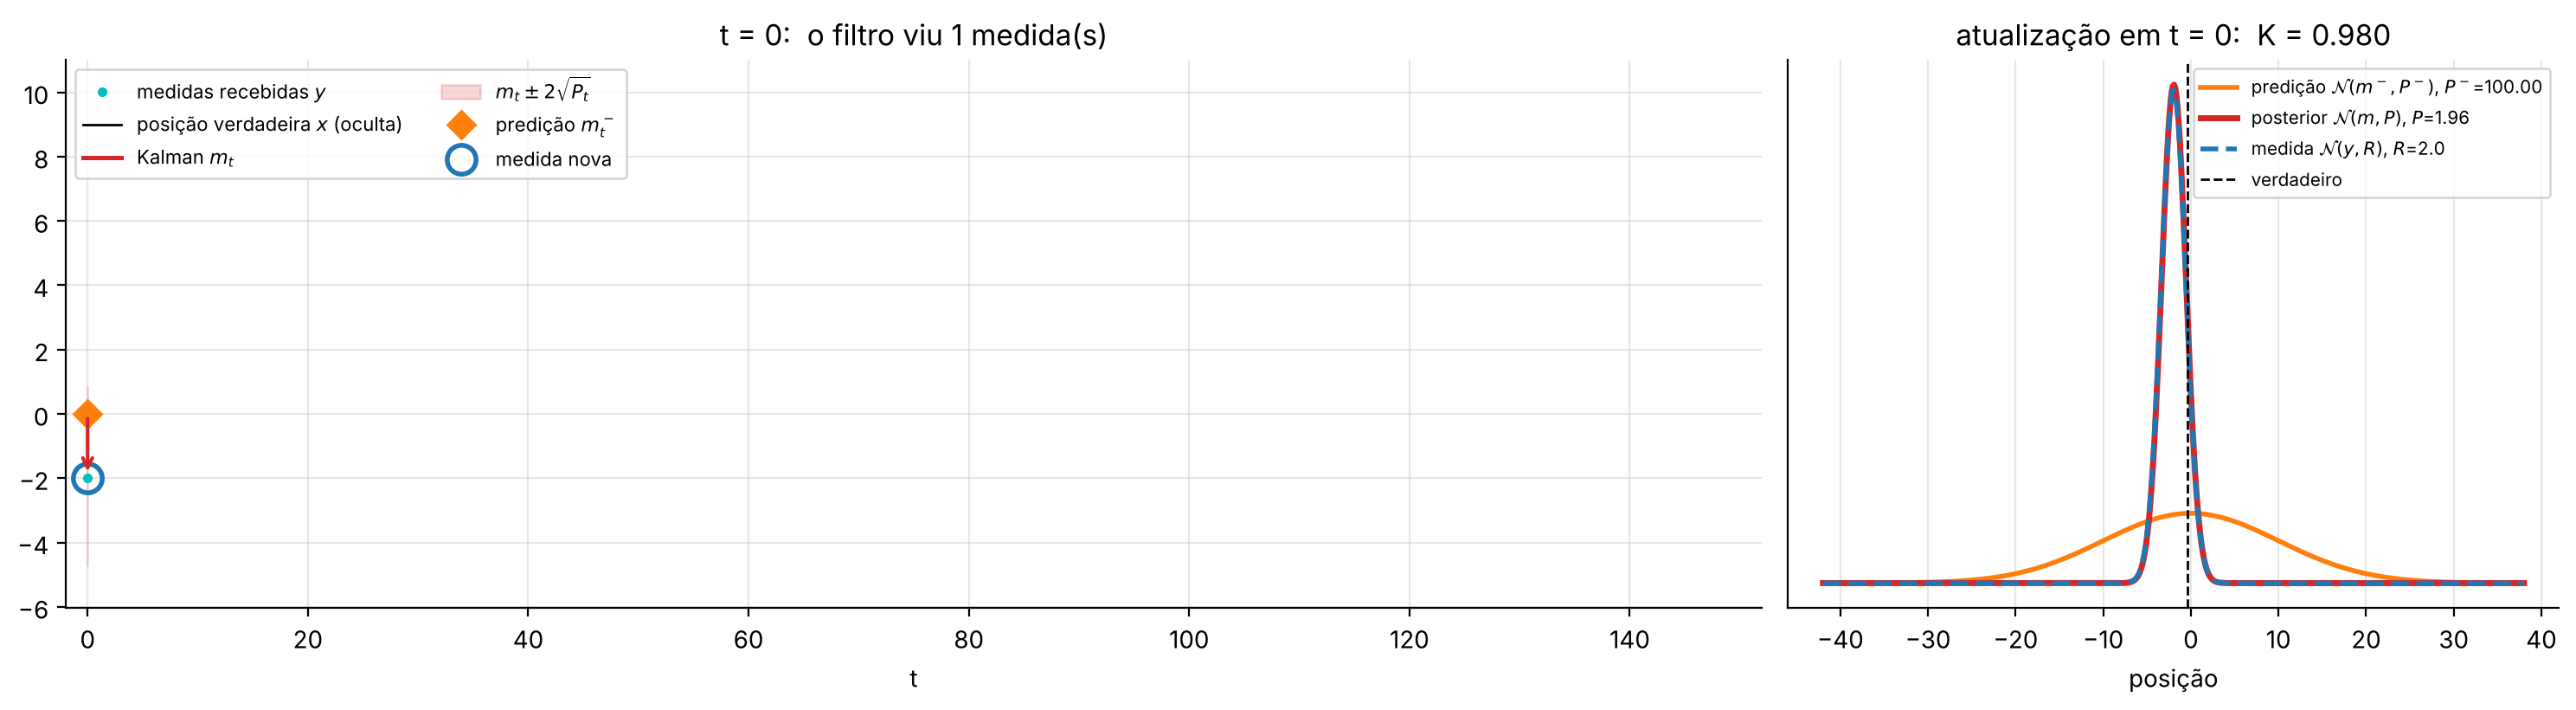

In [15]:
explica(0)
quadro(0)

### Do quadro 0 para o quadro 1: o primeiro ciclo completo

Agora sim há **predição**: a crença de $t=0$ é empurrada para $t=1$. Como $F=1$, a média não muda; a variância cresce de $Q=0{,}3$. Em seguida a nova medida corrige. Compare os dois valores de $P$ impressos: o "dente de serra" começou.

══════════════════  instante t = 1  ══════════════════
Crença anterior (fim de t = 0):  m = -1.945,  P = 1.9608
PREDIÇÃO   m⁻ = F·m = 1 × (-1.945) = -1.945
           P⁻ = F·P·Fᵀ + Q = 1.9608 + 0.3 = 2.2608   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_1 = -0.641
INOVAÇÃO   v = y − H·m⁻ = -0.641 − (-1.945) = +1.305
           S = H·P⁻·Hᵀ + R = 2.2608 + 2.0 = 4.2608   → surpresa em desvios-padrão: v/√S = +0.63
GANHO      K = P⁻·Hᵀ·S⁻¹ = 2.2608 / 4.2608 = 0.5306   (confia mais na MEDIDA)
CORREÇÃO   m = m⁻ + K·v = -1.945 + 0.5306 × (+1.305) = -1.253
           P = P⁻ − K·S·Kᵀ = 2.2608 − 0.5306² × 4.2608 = 1.0612   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-3.313, 0.807]   — posição verdadeira (que o filtro não conhece): -0.303
VEROSSIMILHANÇA   log N(v; 0, S) = -1.843;  acumulada = -5.094


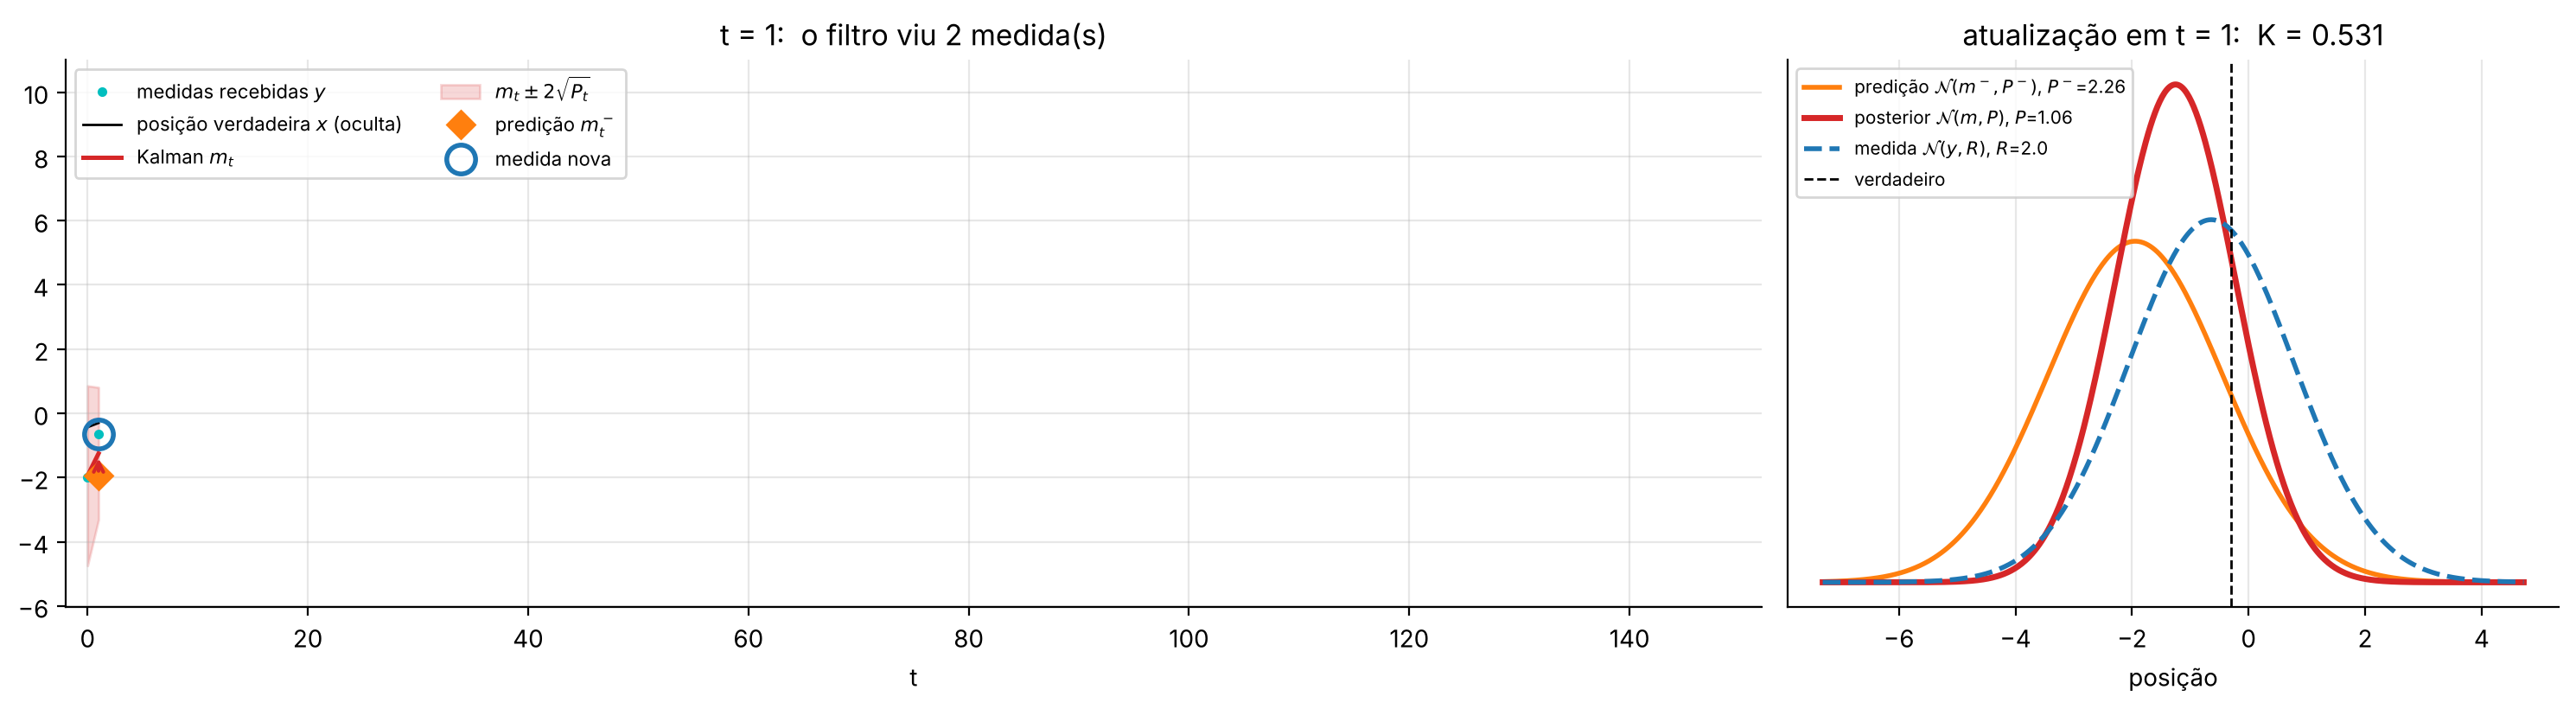

In [16]:
explica(1)
quadro(1)

### Quadro $t=2$

A cada medida, a variância antes da atualização ($P^-$) é menor do que no passo anterior, e o ganho $K$ cai. O filtro passa a confiar mais na sua própria previsão e menos em cada medida isolada.

══════════════════  instante t = 2  ══════════════════
Crença anterior (fim de t = 1):  m = -1.253,  P = 1.0612
PREDIÇÃO   m⁻ = F·m = 1 × (-1.253) = -1.253
           P⁻ = F·P·Fᵀ + Q = 1.0612 + 0.3 = 1.3612   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_2 = -1.490
INOVAÇÃO   v = y − H·m⁻ = -1.490 − (-1.253) = -0.237
           S = H·P⁻·Hᵀ + R = 1.3612 + 2.0 = 3.3612   → surpresa em desvios-padrão: v/√S = -0.13
GANHO      K = P⁻·Hᵀ·S⁻¹ = 1.3612 / 3.3612 = 0.4050   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = -1.253 + 0.4050 × (-0.237) = -1.349
           P = P⁻ − K·S·Kᵀ = 1.3612 − 0.4050² × 3.3612 = 0.8100   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-3.149, 0.451]   — posição verdadeira (que o filtro não conhece): -1.341
VEROSSIMILHANÇA   log N(v; 0, S) = -1.533;  acumulada = -6.628


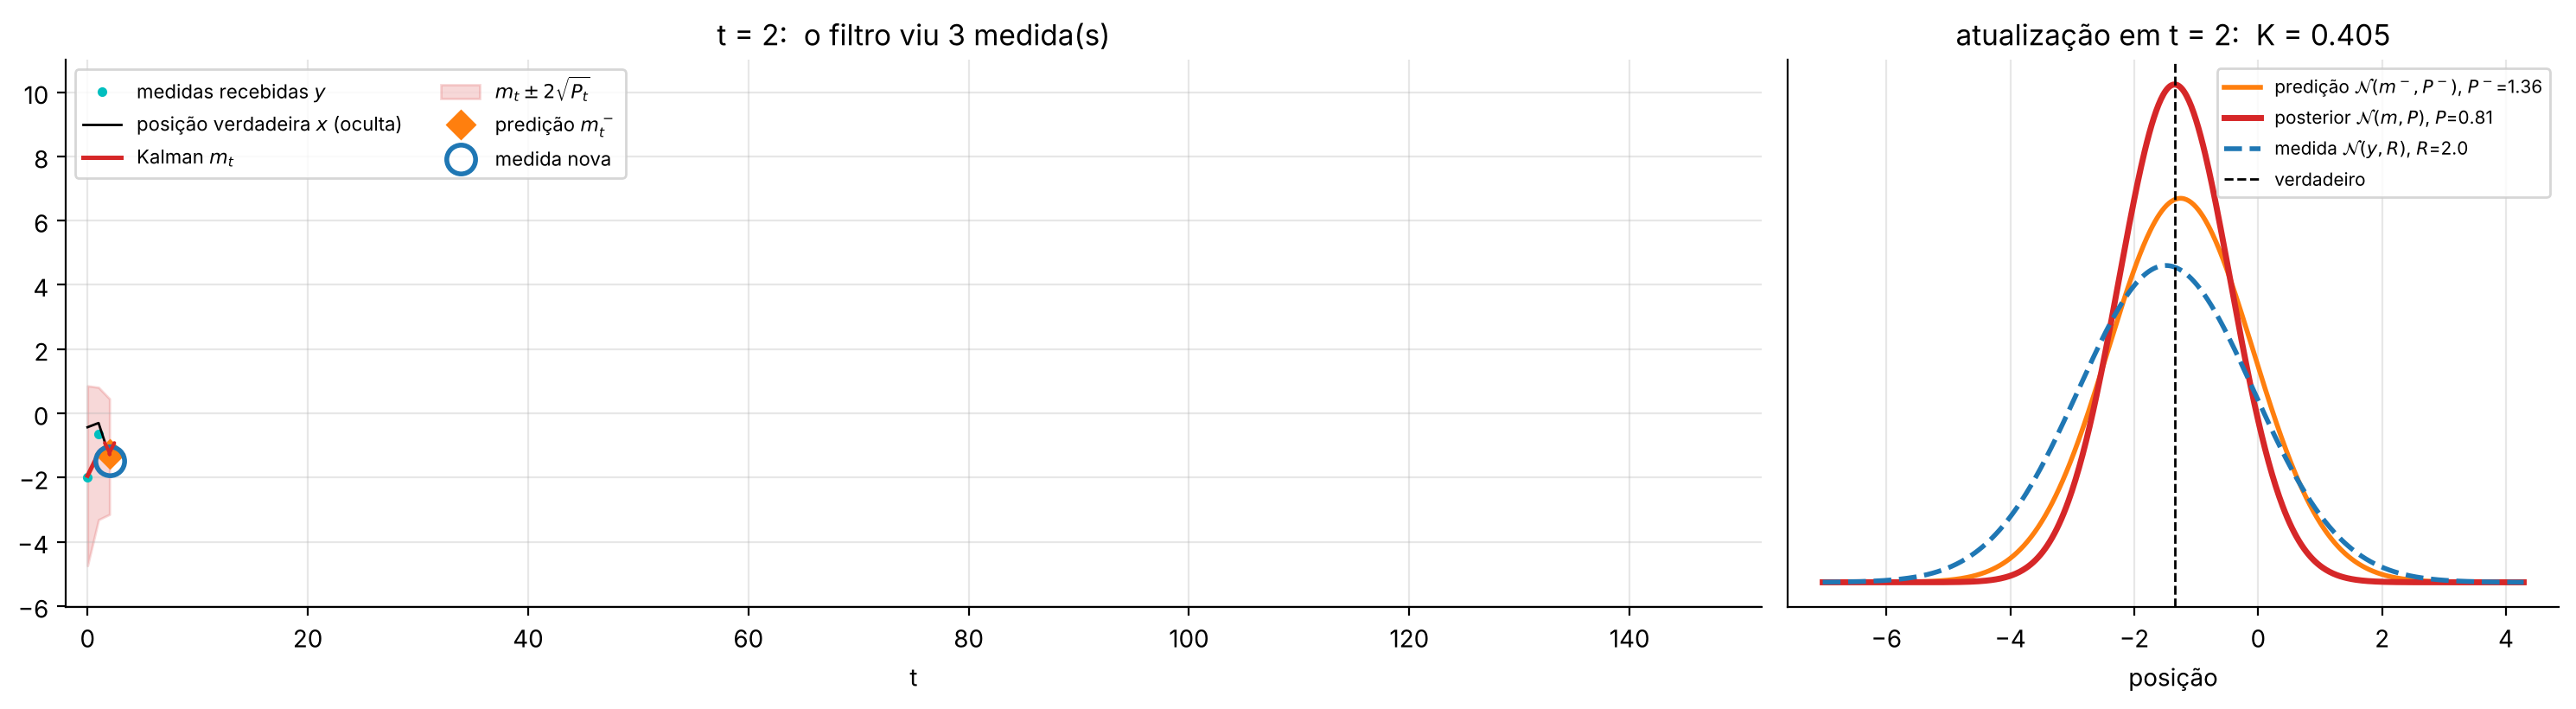

In [17]:
explica(2)
quadro(2)

### Quadro $t=3$

Observe no painel da direita que a posterior é sempre **mais estreita que as duas curvas** que a geraram. Combinar duas fontes independentes de informação sempre reduz a incerteza: as precisões se somam, $1/P = 1/P^- + 1/R$.

══════════════════  instante t = 3  ══════════════════
Crença anterior (fim de t = 2):  m = -1.349,  P = 0.8100
PREDIÇÃO   m⁻ = F·m = 1 × (-1.349) = -1.349
           P⁻ = F·P·Fᵀ + Q = 0.8100 + 0.3 = 1.1100   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_3 = -1.782
INOVAÇÃO   v = y − H·m⁻ = -1.782 − (-1.349) = -0.433
           S = H·P⁻·Hᵀ + R = 1.1100 + 2.0 = 3.1100   → surpresa em desvios-padrão: v/√S = -0.25
GANHO      K = P⁻·Hᵀ·S⁻¹ = 1.1100 / 3.1100 = 0.3569   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = -1.349 + 0.3569 × (-0.433) = -1.504
           P = P⁻ − K·S·Kᵀ = 1.1100 − 0.3569² × 3.1100 = 0.7138   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-3.193, 0.186]   — posição verdadeira (que o filtro não conhece): -0.577
VEROSSIMILHANÇA   log N(v; 0, S) = -1.516;  acumulada = -8.144


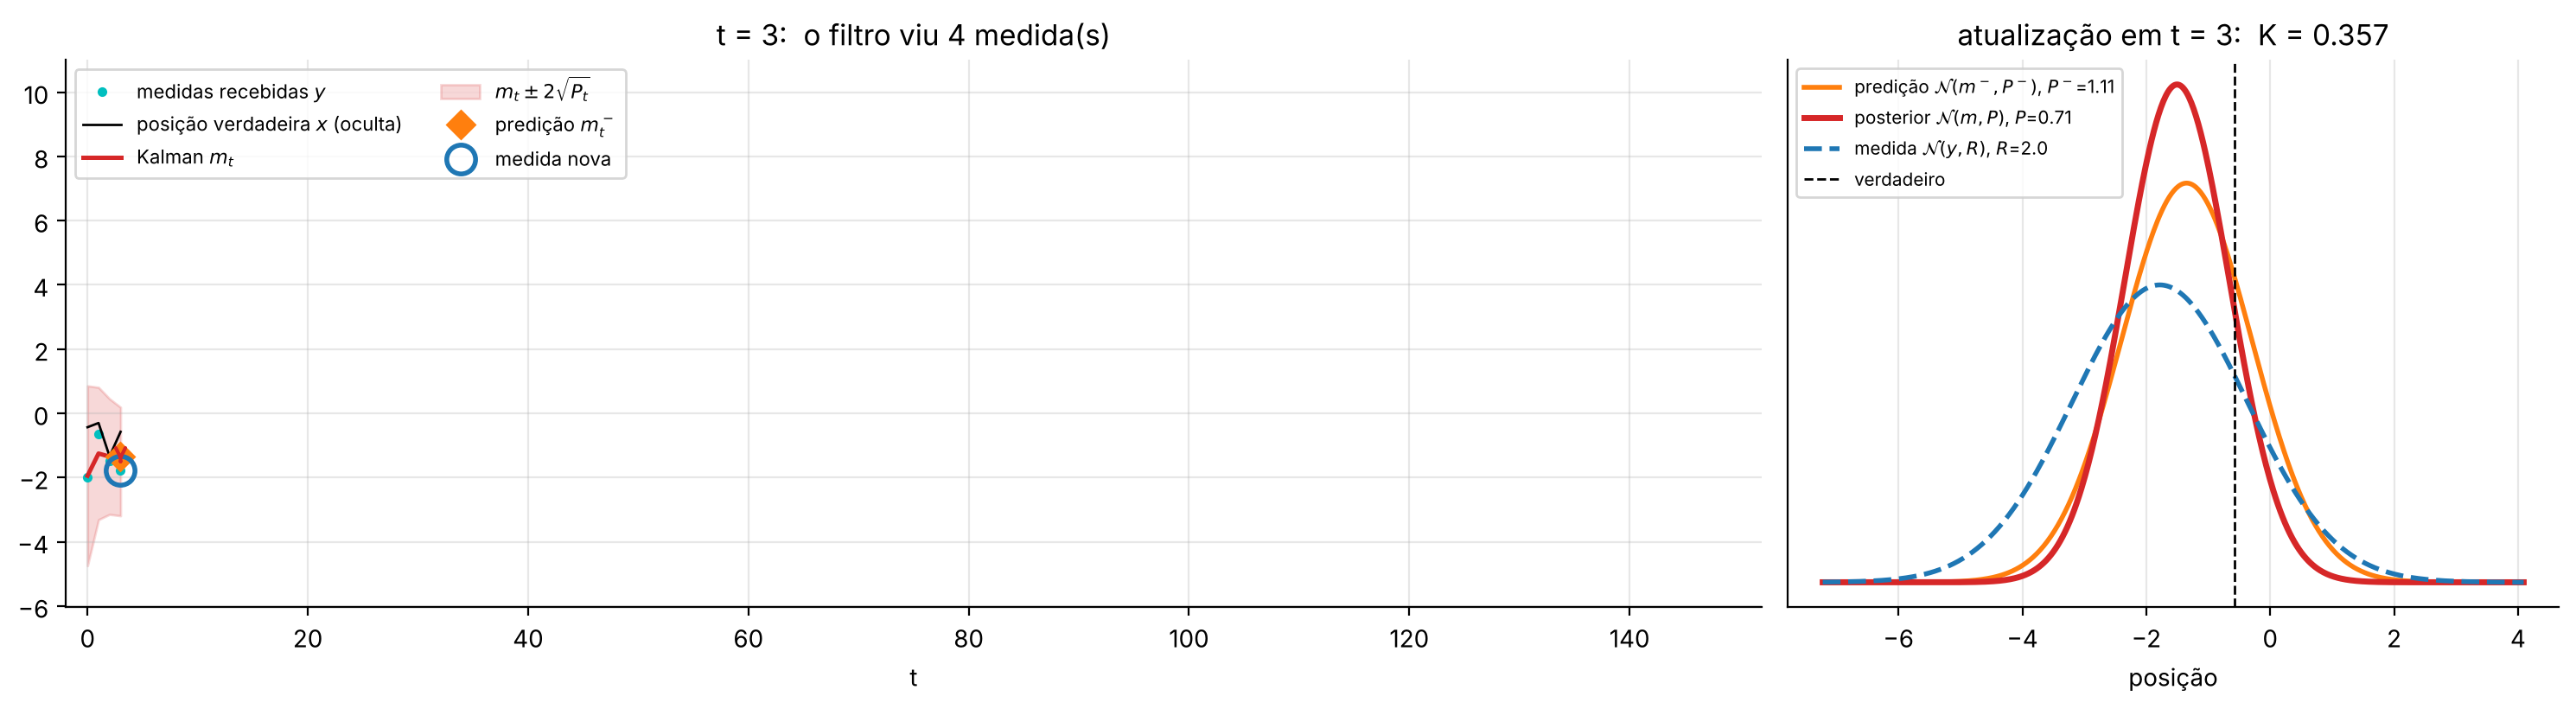

In [18]:
explica(3)
quadro(3)

### Quadro $t=4$

Na expressão $m = m^- + K v$, olhe o sinal da inovação $v$: quando a medida cai acima da previsão ($v>0$), a correção puxa a estimativa para cima, e vice-versa. A seta no painel da esquerda mostra exatamente esse puxão.

══════════════════  instante t = 4  ══════════════════
Crença anterior (fim de t = 3):  m = -1.504,  P = 0.7138
PREDIÇÃO   m⁻ = F·m = 1 × (-1.504) = -1.504
           P⁻ = F·P·Fᵀ + Q = 0.7138 + 0.3 = 1.0138   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_4 = 0.974
INOVAÇÃO   v = y − H·m⁻ = 0.974 − (-1.504) = +2.477
           S = H·P⁻·Hᵀ + R = 1.0138 + 2.0 = 3.0138   → surpresa em desvios-padrão: v/√S = +1.43
GANHO      K = P⁻·Hᵀ·S⁻¹ = 1.0138 / 3.0138 = 0.3364   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = -1.504 + 0.3364 × (+2.477) = -0.670
           P = P⁻ − K·S·Kᵀ = 1.0138 − 0.3364² × 3.0138 = 0.6728   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-2.311, 0.970]   — posição verdadeira (que o filtro não conhece): -0.227
VEROSSIMILHANÇA   log N(v; 0, S) = -2.489;  acumulada = -10.633


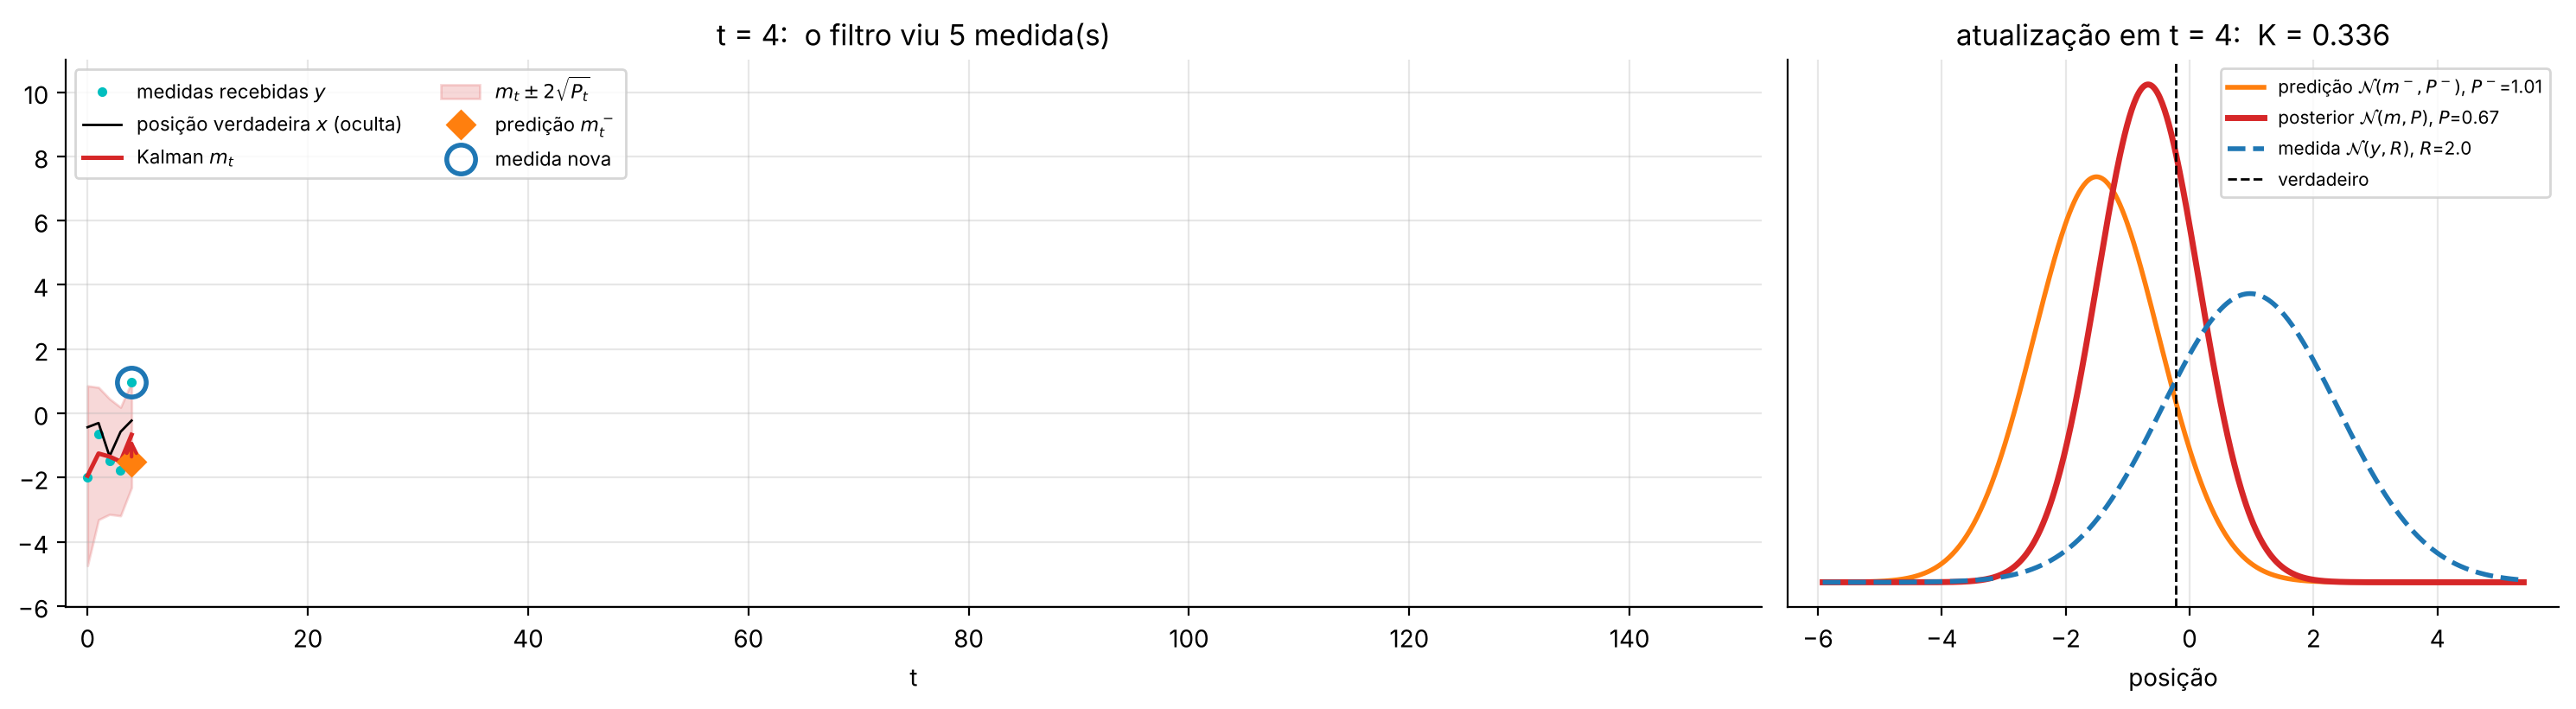

In [19]:
explica(4)
quadro(4)

### Quadro $t=5$

Depois de poucas medidas, $P$ já está perto do valor em que vai se estabilizar. A faixa vermelha deixou de encolher.

══════════════════  instante t = 5  ══════════════════
Crença anterior (fim de t = 4):  m = -0.670,  P = 0.6728
PREDIÇÃO   m⁻ = F·m = 1 × (-0.670) = -0.670
           P⁻ = F·P·Fᵀ + Q = 0.6728 + 0.3 = 0.9728   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_5 = -2.405
INOVAÇÃO   v = y − H·m⁻ = -2.405 − (-0.670) = -1.734
           S = H·P⁻·Hᵀ + R = 0.9728 + 2.0 = 2.9728   → surpresa em desvios-padrão: v/√S = -1.01
GANHO      K = P⁻·Hᵀ·S⁻¹ = 0.9728 / 2.9728 = 0.3272   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = -0.670 + 0.3272 × (-1.734) = -1.238
           P = P⁻ − K·S·Kᵀ = 0.9728 − 0.3272² × 2.9728 = 0.6545   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-2.856, 0.380]   — posição verdadeira (que o filtro não conhece): -0.387
VEROSSIMILHANÇA   log N(v; 0, S) = -1.970;  acumulada = -12.602


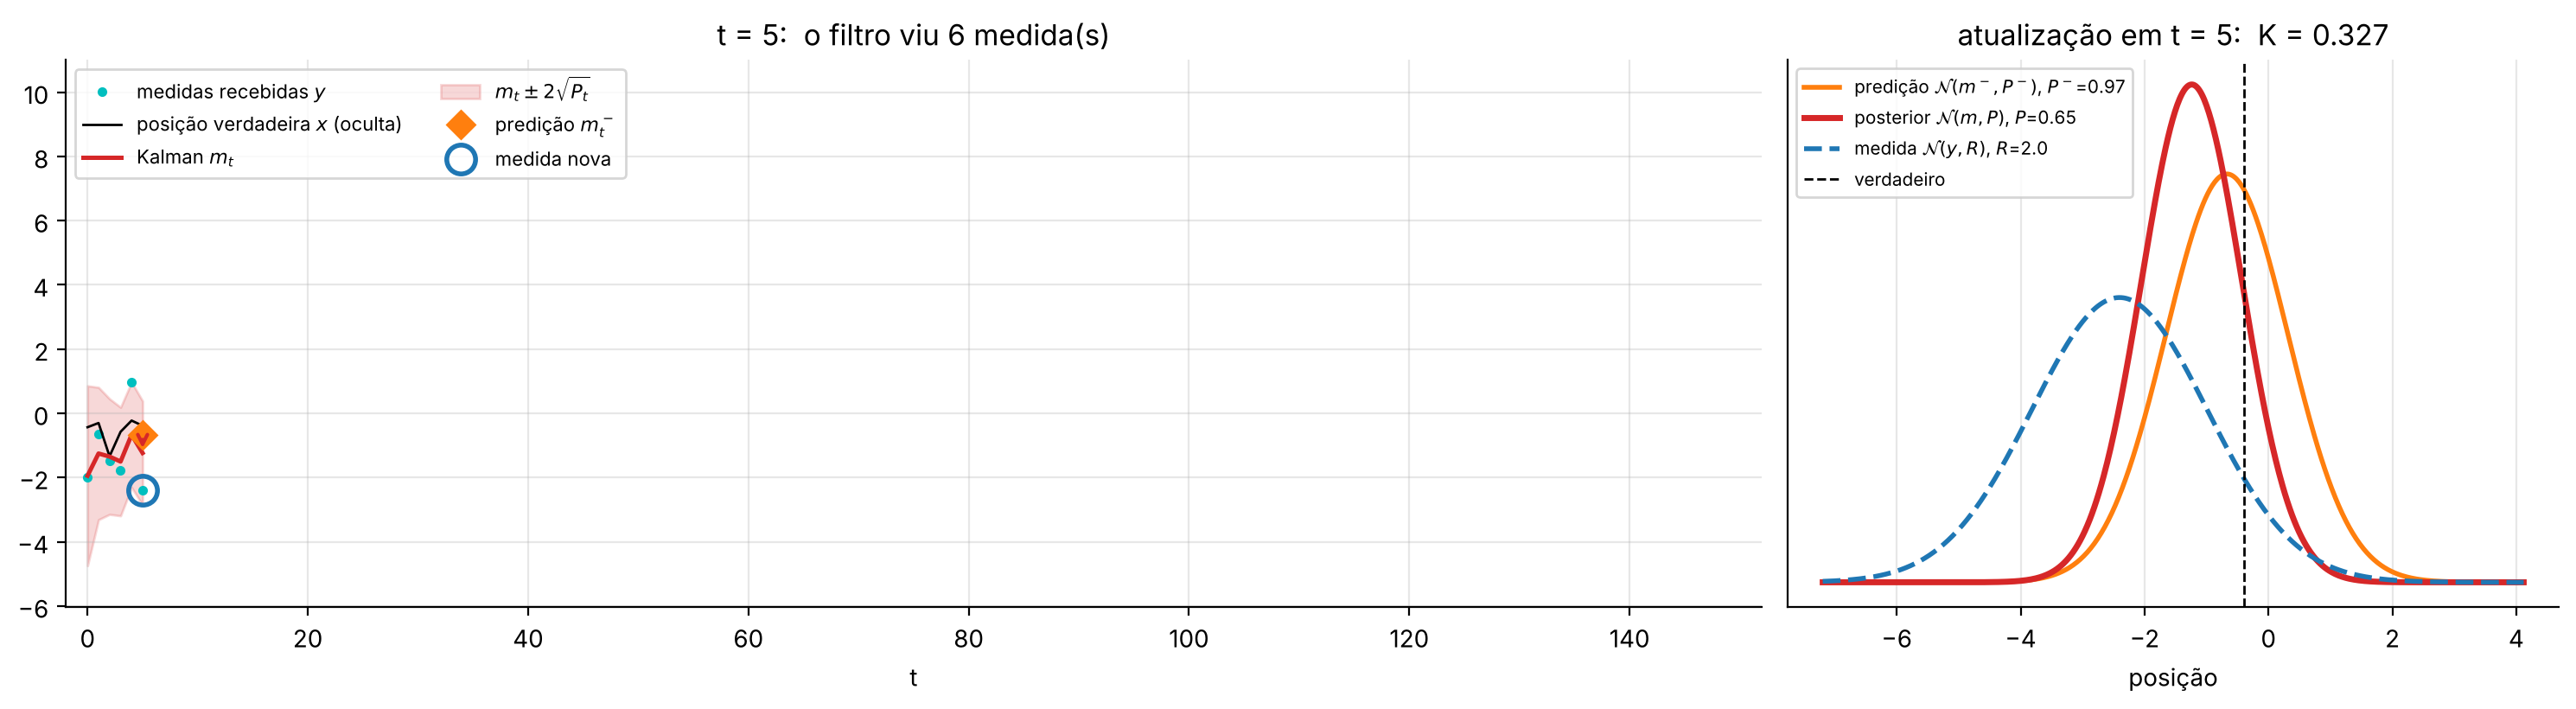

In [20]:
explica(5)
quadro(5)

### Pulando para $t=10$

Entre os quadros 5 e 10 o filtro fez mais cinco ciclos idênticos (predição → medida → atualização). O ganho já está praticamente no **valor estacionário**: a incerteza que a predição acrescenta ($Q$) é exatamente compensada pela que a medida retira.

══════════════════  instante t = 10  ══════════════════
Crença anterior (fim de t = 9):  m = -0.756,  P = 0.6397
PREDIÇÃO   m⁻ = F·m = 1 × (-0.756) = -0.756
           P⁻ = F·P·Fᵀ + Q = 0.6397 + 0.3 = 0.9397   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_10 = 0.611
INOVAÇÃO   v = y − H·m⁻ = 0.611 − (-0.756) = +1.367
           S = H·P⁻·Hᵀ + R = 0.9397 + 2.0 = 2.9397   → surpresa em desvios-padrão: v/√S = +0.80
GANHO      K = P⁻·Hᵀ·S⁻¹ = 0.9397 / 2.9397 = 0.3197   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = -0.756 + 0.3197 × (+1.367) = -0.319
           P = P⁻ − K·S·Kᵀ = 0.9397 − 0.3197² × 2.9397 = 0.6393   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-1.918, 1.280]   — posição verdadeira (que o filtro não conhece): -0.268
VEROSSIMILHANÇA   log N(v; 0, S) = -1.776;  acumulada = -22.417


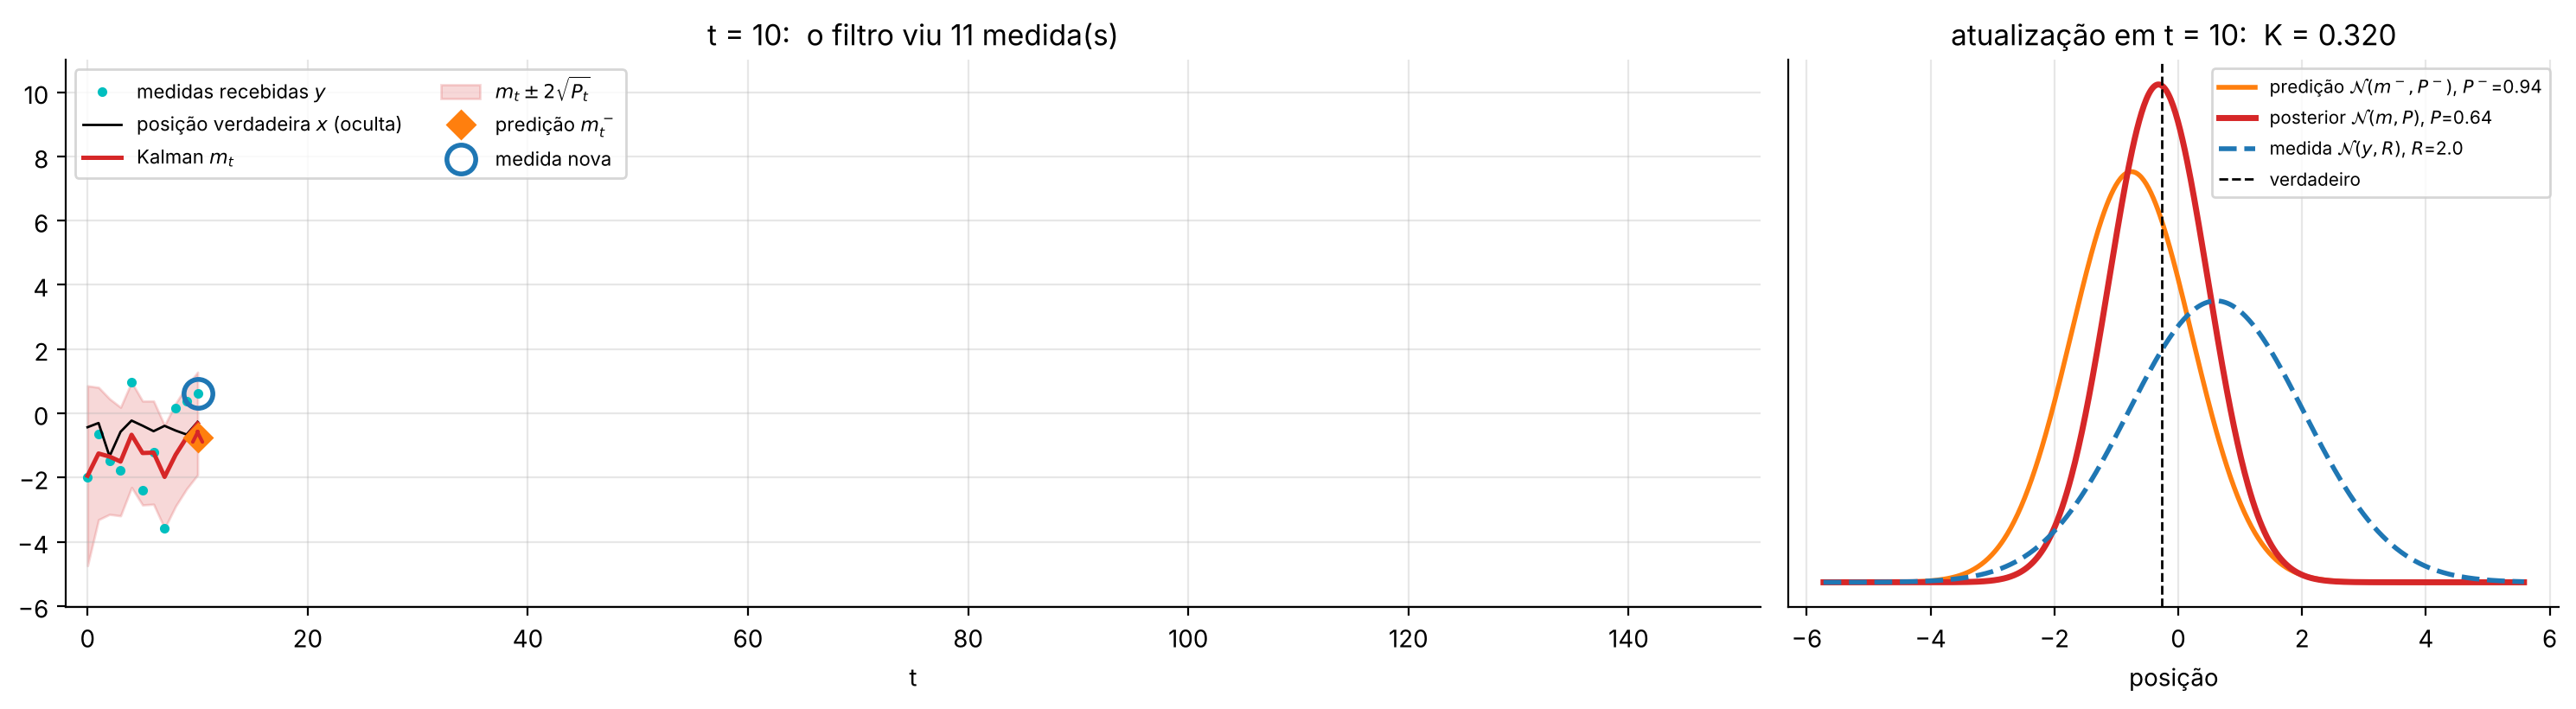

In [21]:
explica(10)
quadro(10)

### Quadro $t=20$

Note que a curva vermelha é **mais lisa que as medidas** e acompanha a posição verdadeira com atraso pequeno. É o compromisso controlado por $Q/R$: quanto maior $Q$ em relação a $R$, mais o filtro segue as medidas; quanto menor, mais ele suaviza.

══════════════════  instante t = 20  ══════════════════
Crença anterior (fim de t = 19):  m = 0.233,  P = 0.6390
PREDIÇÃO   m⁻ = F·m = 1 × 0.233 = 0.233
           P⁻ = F·P·Fᵀ + Q = 0.6390 + 0.3 = 0.9390   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_20 = -0.821
INOVAÇÃO   v = y − H·m⁻ = -0.821 − 0.233 = -1.054
           S = H·P⁻·Hᵀ + R = 0.9390 + 2.0 = 2.9390   → surpresa em desvios-padrão: v/√S = -0.61
GANHO      K = P⁻·Hᵀ·S⁻¹ = 0.9390 / 2.9390 = 0.3195   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = 0.233 + 0.3195 × (-1.054) = -0.103
           P = P⁻ − K·S·Kᵀ = 0.9390 − 0.3195² × 2.9390 = 0.6390   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-1.702, 1.495]   — posição verdadeira (que o filtro não conhece): -1.322
VEROSSIMILHANÇA   log N(v; 0, S) = -1.647;  acumulada = -46.288


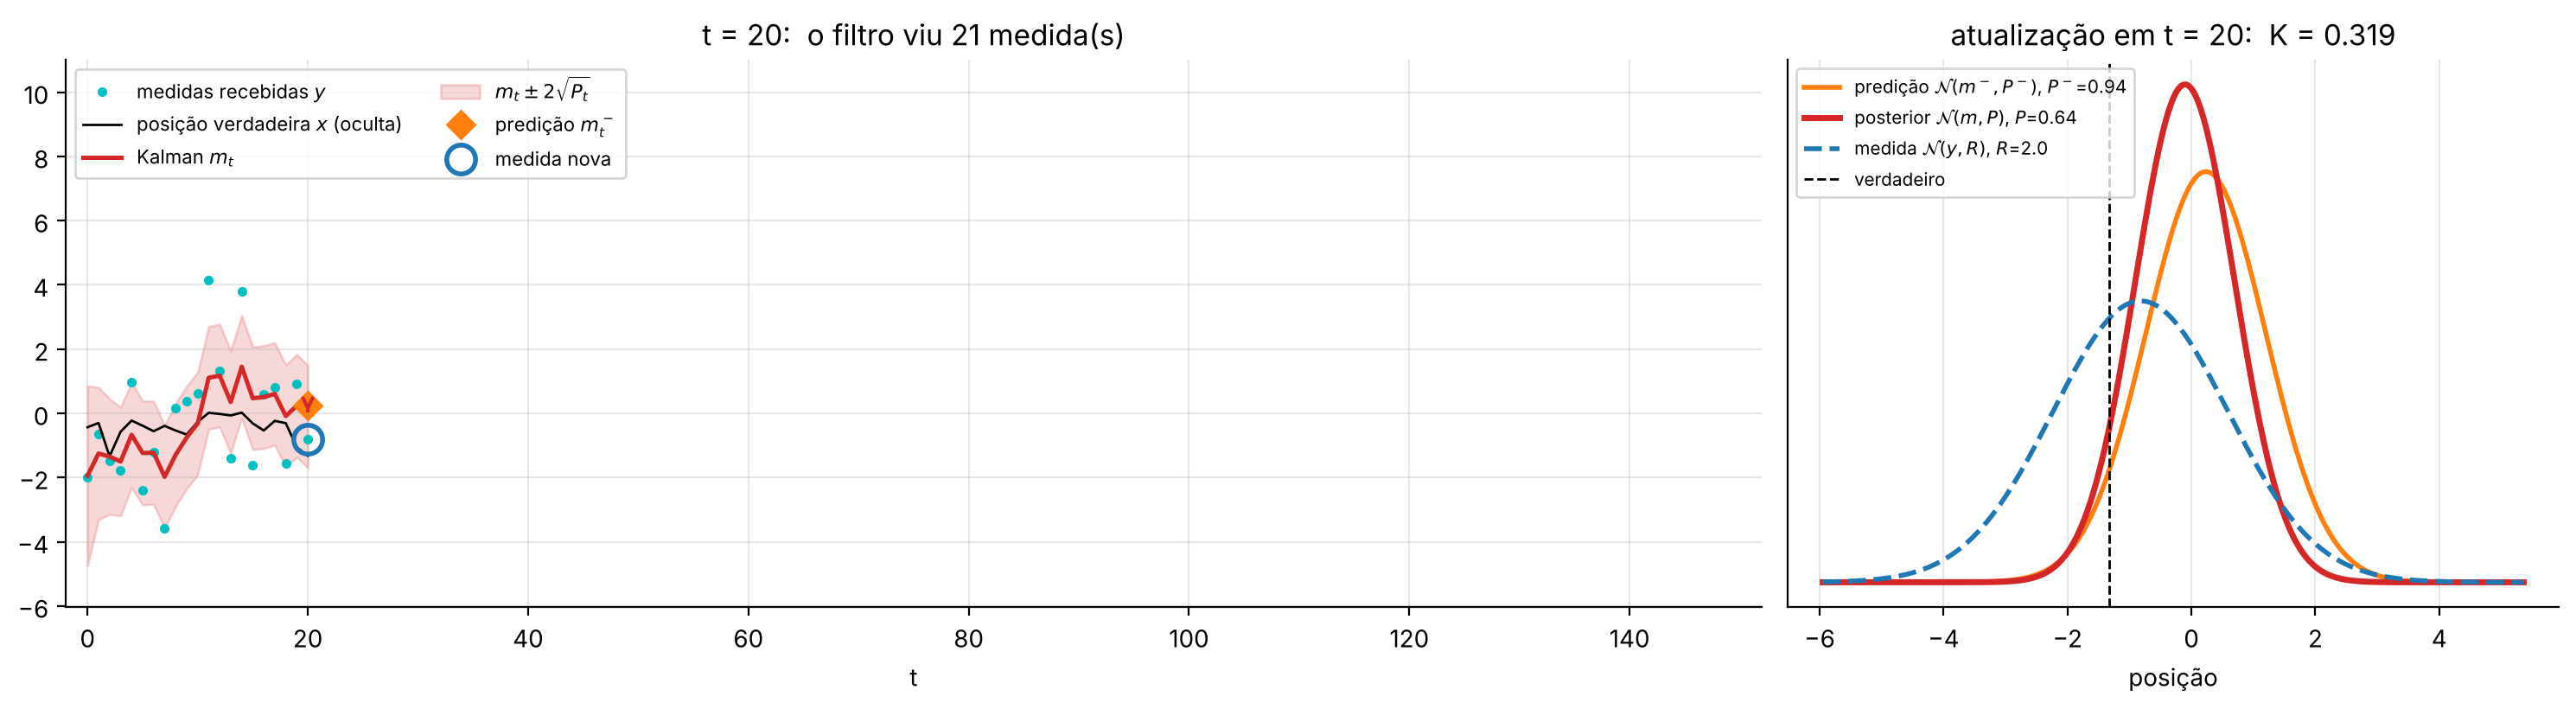

In [22]:
explica(20)
quadro(20)

### Quadro $t=40$

Verifique visualmente a **calibração**: a linha preta (verdade) deveria ficar dentro da faixa de $\pm2\sigma$ em cerca de 95% dos instantes. A contagem é feita na última seção.

══════════════════  instante t = 40  ══════════════════
Crença anterior (fim de t = 39):  m = 0.215,  P = 0.6390
PREDIÇÃO   m⁻ = F·m = 1 × 0.215 = 0.215
           P⁻ = F·P·Fᵀ + Q = 0.6390 + 0.3 = 0.9390   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_40 = 1.516
INOVAÇÃO   v = y − H·m⁻ = 1.516 − 0.215 = +1.302
           S = H·P⁻·Hᵀ + R = 0.9390 + 2.0 = 2.9390   → surpresa em desvios-padrão: v/√S = +0.76
GANHO      K = P⁻·Hᵀ·S⁻¹ = 0.9390 / 2.9390 = 0.3195   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = 0.215 + 0.3195 × (+1.302) = 0.631
           P = P⁻ − K·S·Kᵀ = 0.9390 − 0.3195² × 2.9390 = 0.6390   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [-0.968, 2.229]   — posição verdadeira (que o filtro não conhece): 1.354
VEROSSIMILHANÇA   log N(v; 0, S) = -1.746;  acumulada = -88.792


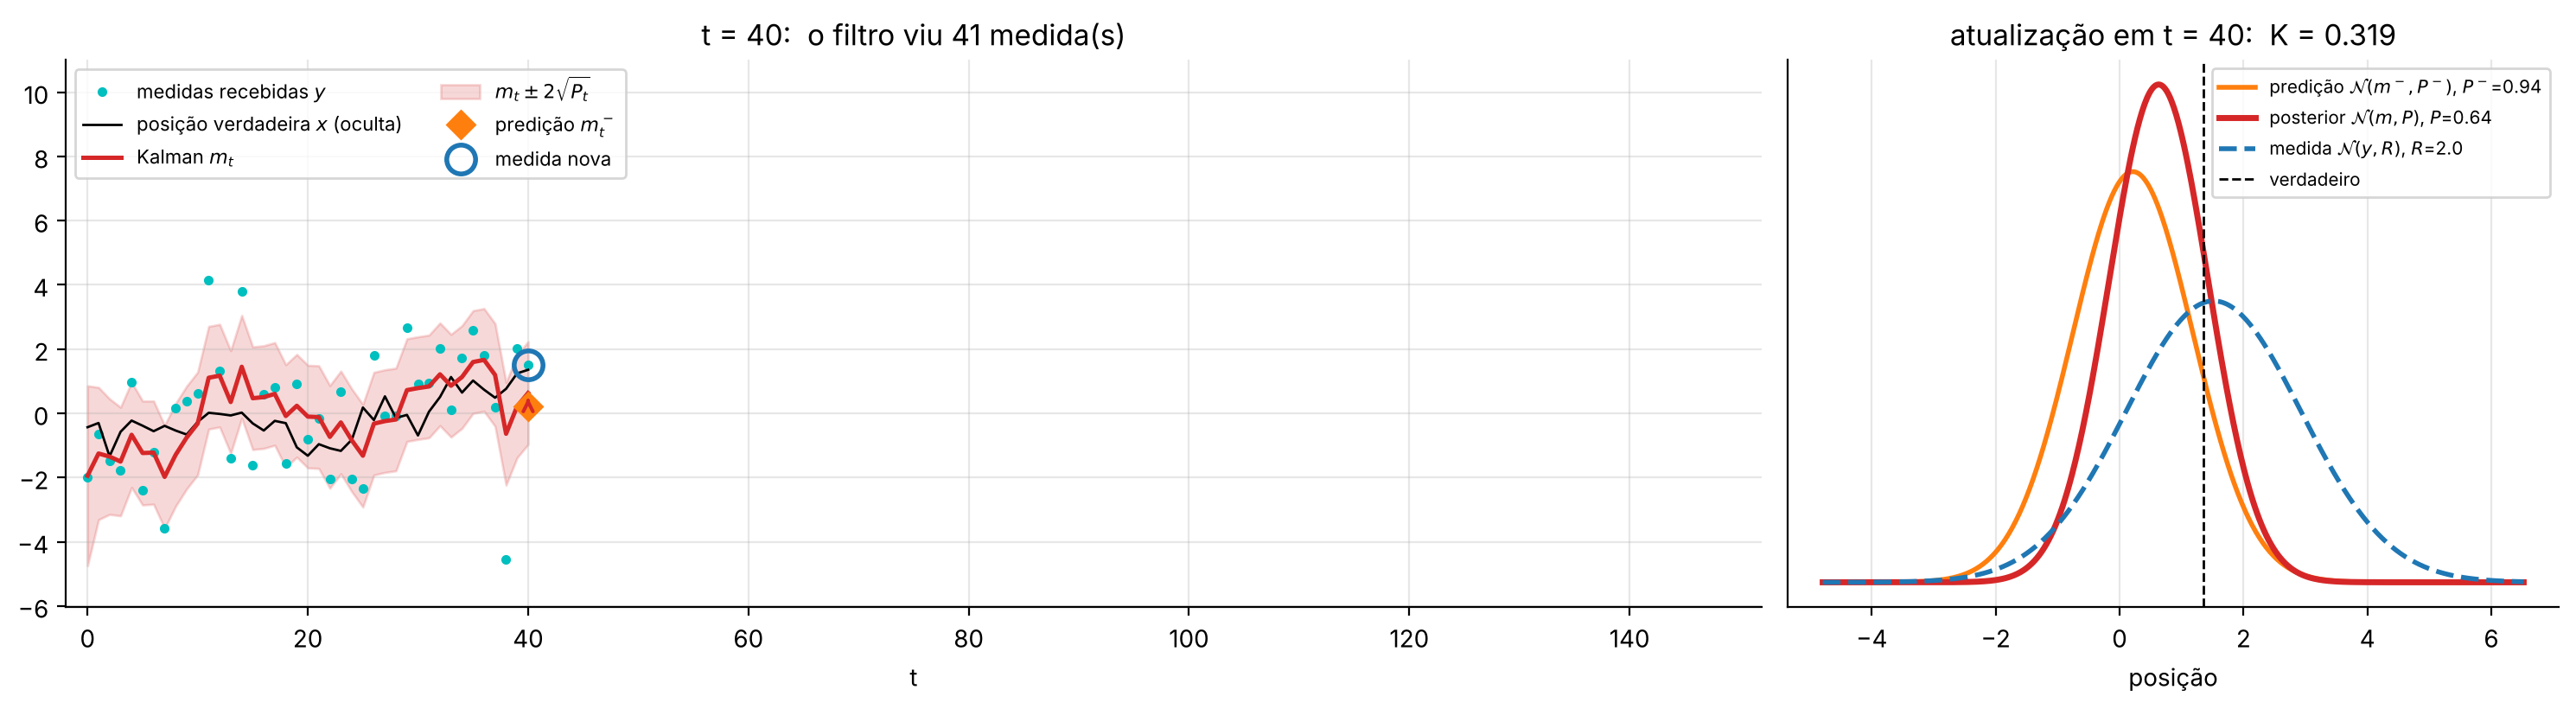

In [23]:
explica(40)
quadro(40)

### Quadro $t=80$

O regime é estacionário: $P^-$, $S$, $K$ e $P$ impressos são praticamente os mesmos de qualquer instante recente. Apenas $m$, $y$ e $v$ mudam.

══════════════════  instante t = 80  ══════════════════
Crença anterior (fim de t = 79):  m = 4.255,  P = 0.6390
PREDIÇÃO   m⁻ = F·m = 1 × 4.255 = 4.255
           P⁻ = F·P·Fᵀ + Q = 0.6390 + 0.3 = 0.9390   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_80 = 5.799
INOVAÇÃO   v = y − H·m⁻ = 5.799 − 4.255 = +1.544
           S = H·P⁻·Hᵀ + R = 0.9390 + 2.0 = 2.9390   → surpresa em desvios-padrão: v/√S = +0.90
GANHO      K = P⁻·Hᵀ·S⁻¹ = 0.9390 / 2.9390 = 0.3195   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = 4.255 + 0.3195 × (+1.544) = 4.748
           P = P⁻ − K·S·Kᵀ = 0.9390 − 0.3195² × 2.9390 = 0.6390   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [3.150, 6.347]   — posição verdadeira (que o filtro não conhece): 6.101
VEROSSIMILHANÇA   log N(v; 0, S) = -1.863;  acumulada = -164.803


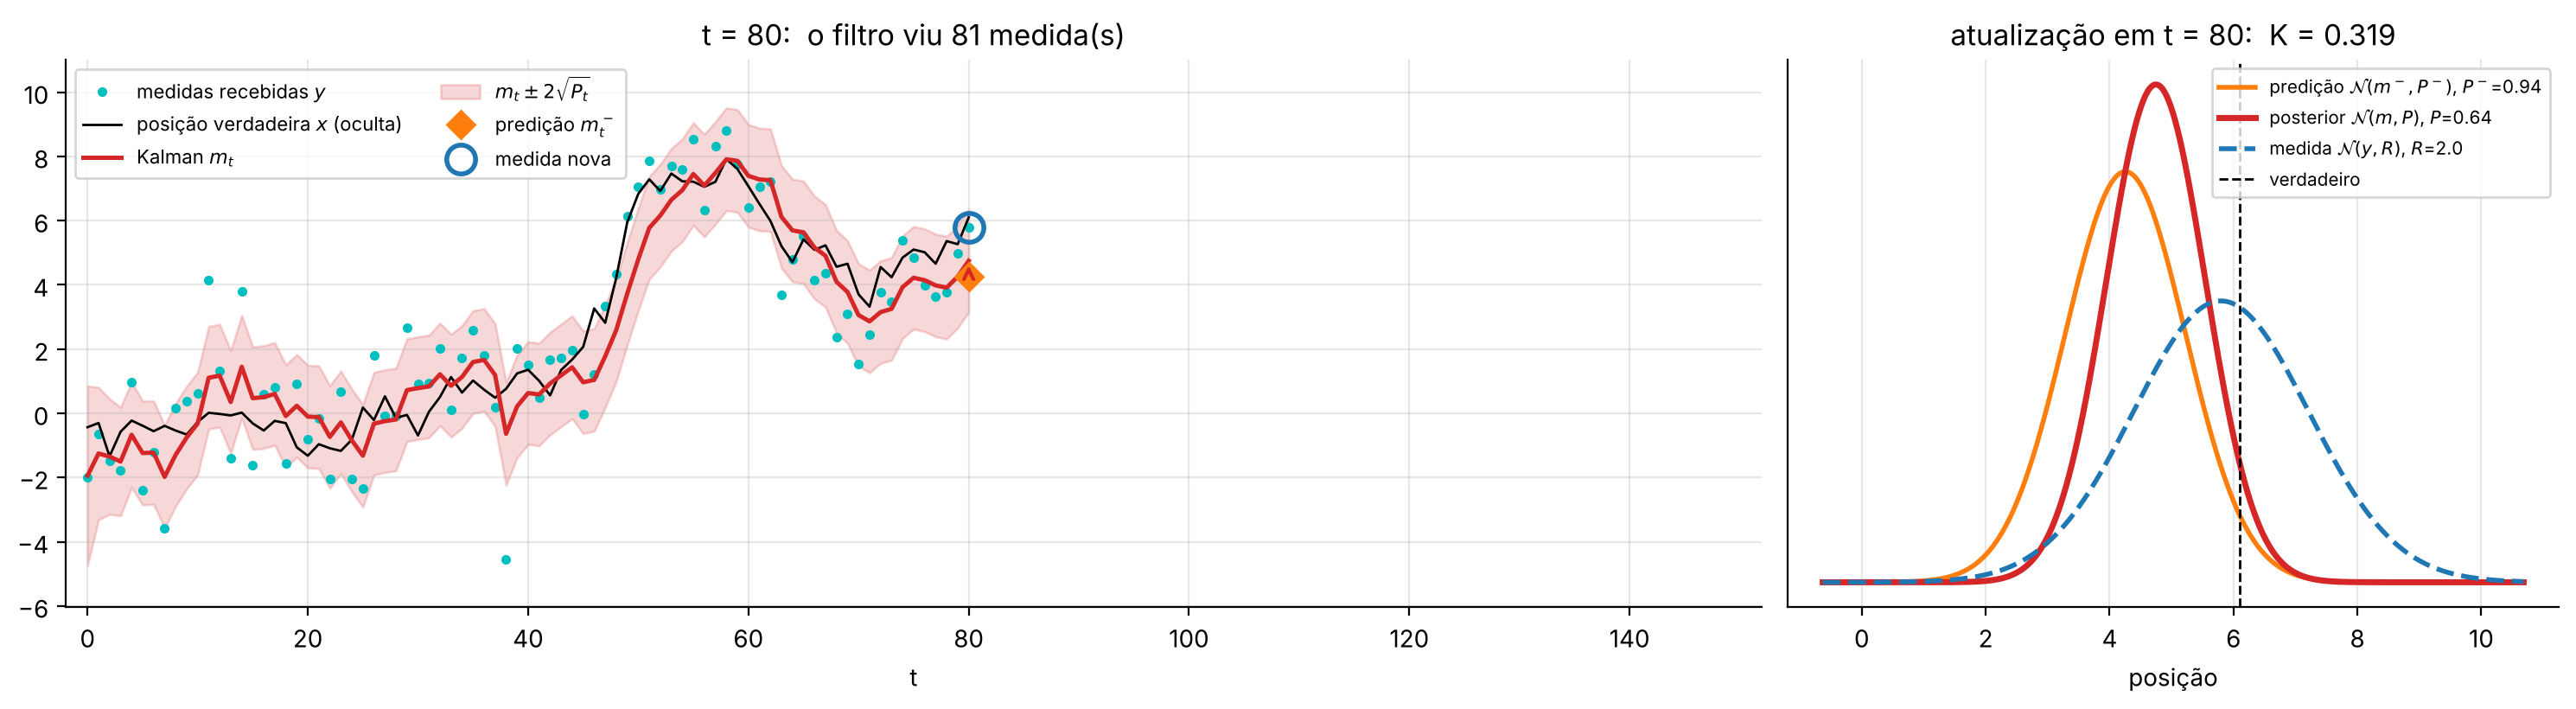

In [24]:
explica(80)
quadro(80)

### Último quadro, $t=149$

O filtro processou as 150 medidas, uma de cada vez, guardando apenas $(m,P)$. O gráfico é o mesmo do programa original (painel esquerdo da figura da seção 5), mas construído **sem nunca olhar para o futuro**.

══════════════════  instante t = 149  ══════════════════
Crença anterior (fim de t = 148):  m = 6.181,  P = 0.6390
PREDIÇÃO   m⁻ = F·m = 1 × 6.181 = 6.181
           P⁻ = F·P·Fᵀ + Q = 0.6390 + 0.3 = 0.9390   (a incerteza CRESCE: o bêbado deu um passo que não vimos)
CHEGA A MEDIDA   y_149 = 5.793
INOVAÇÃO   v = y − H·m⁻ = 5.793 − 6.181 = -0.388
           S = H·P⁻·Hᵀ + R = 0.9390 + 2.0 = 2.9390   → surpresa em desvios-padrão: v/√S = -0.23
GANHO      K = P⁻·Hᵀ·S⁻¹ = 0.9390 / 2.9390 = 0.3195   (confia mais na PREVISÃO)
CORREÇÃO   m = m⁻ + K·v = 6.181 + 0.3195 × (-0.388) = 6.057
           P = P⁻ − K·S·Kᵀ = 0.9390 − 0.3195² × 2.9390 = 0.6390   (a incerteza DIMINUI: ganhamos informação)
           faixa ±2σ: [4.458, 7.655]   — posição verdadeira (que o filtro não conhece): 5.414
VEROSSIMILHANÇA   log N(v; 0, S) = -1.484;  acumulada = -310.558


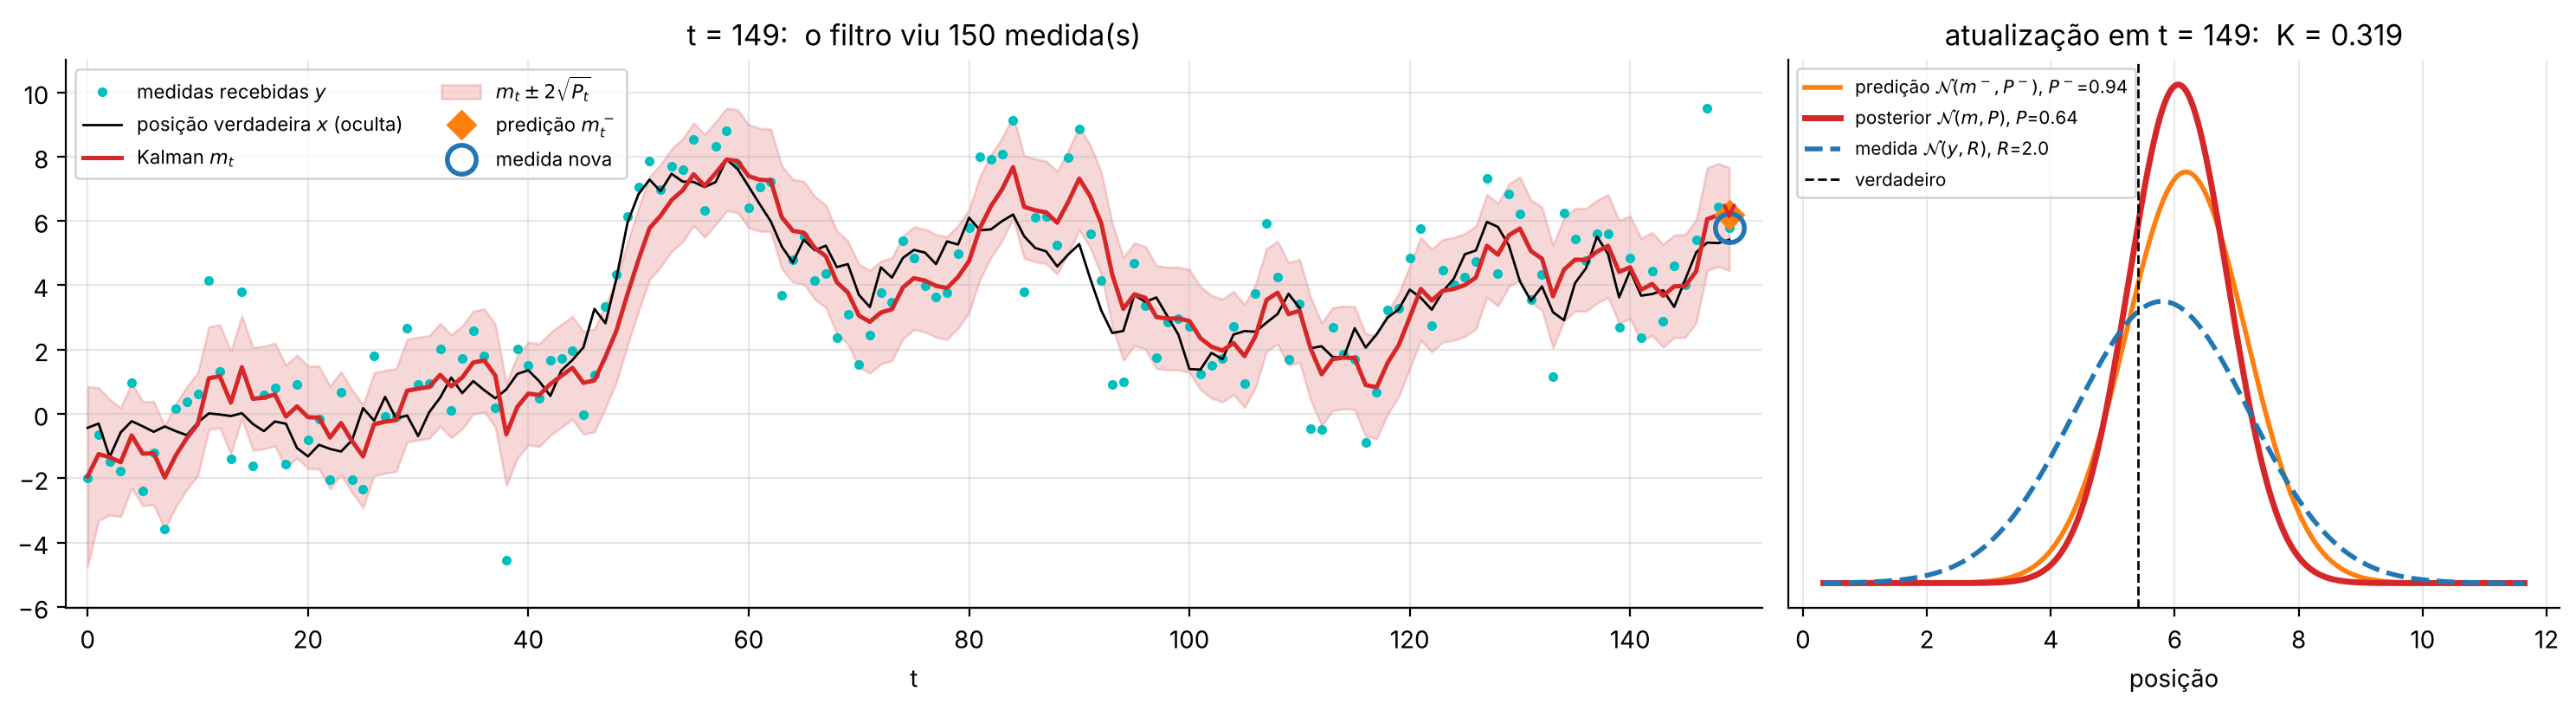

In [25]:
explica(149)
quadro(149)

### Opcional: um controle deslizante

No Jupyter ou no Colab, a célula abaixo cria um controle para percorrer **todos** os instantes. Se `ipywidgets` não estiver disponível, ela apenas avisa.

In [26]:
try:
    from ipywidgets import interact, IntSlider
    interact(lambda t: (explica(t), quadro(t)), t=IntSlider(min=0, max=T1 - 1, step=1, value=0))
except ImportError:
    print("ipywidgets não está instalado; use explica(t) e quadro(t) diretamente.")

ipywidgets não está instalado; use explica(t) e quadro(t) diretamente.


---
# 5. A figura final do programa original

```python
kf0 = kalman(y1[:, None], I1, I1, 0*I1, r1*I1, np.zeros(1), 100*I1)     # Q = 0: volta à média de A1
```

É o mesmo filtro com **$Q=0$**: o modelo afirma que o bêbado **não se mexe**. Então $P$ nunca cresce na predição, o ganho cai como $1/k$, e o filtro calcula a **média de todas as medidas** desde o início (seção A1 do notebook principal). Como o bêbado de fato se mexe, essa estimativa fica atrasada e "congela".

Agora o código do gráfico, linha a linha:

| código | o que faz |
|---|---|
| `fig, ax = plt.subplots(1, 2, figsize=(13, 4))` | cria uma figura com 1 linha e 2 colunas de painéis, de 13 × 4 polegadas; `ax[0]` e `ax[1]` são os painéis |
| `sd = np.sqrt(kf1["Pf"][:, 0, 0])` | `kf1["Pf"]` tem formato (150, 1, 1); `[:, 0, 0]` extrai a variância de cada instante como vetor (150,); a raiz quadrada dá o desvio-padrão |
| `ax[0].plot(y1, "c.", ms=4, ...)` | medidas como pontos (`.`) ciano (`c`), tamanho 4 |
| `ax[0].plot(x1, "k-", lw=1, ...)` | verdade como linha (`-`) preta (`k`), espessura 1 |
| `ax[0].plot(kf1["mf"][:, 0], "C3", ...)` | estimativa filtrada; `"C3"` é a 4ª cor do ciclo padrão (vermelho) |
| `ax[0].fill_between(range(T1), m-2*sd, m+2*sd, color="C3", alpha=.2)` | pinta a faixa entre $m-2\sigma$ e $m+2\sigma$, com transparência `alpha=.2` |
| `ax[0].plot(kf0["mf"][:, 0], "C2--", ...)` | o filtro com $Q=0$, em verde tracejado |
| `ax[1].plot(kf1["K"][:, 0, 0], ...)` | `kf1["K"]` tem formato (150, 1, 1); extrai o ganho de cada instante |
| `ax[1].set_yscale("log")` | eixo vertical logarítmico, para que $1/k$ apareça como reta |
| `plt.tight_layout(); plt.show()` | ajusta os espaçamentos e desenha |

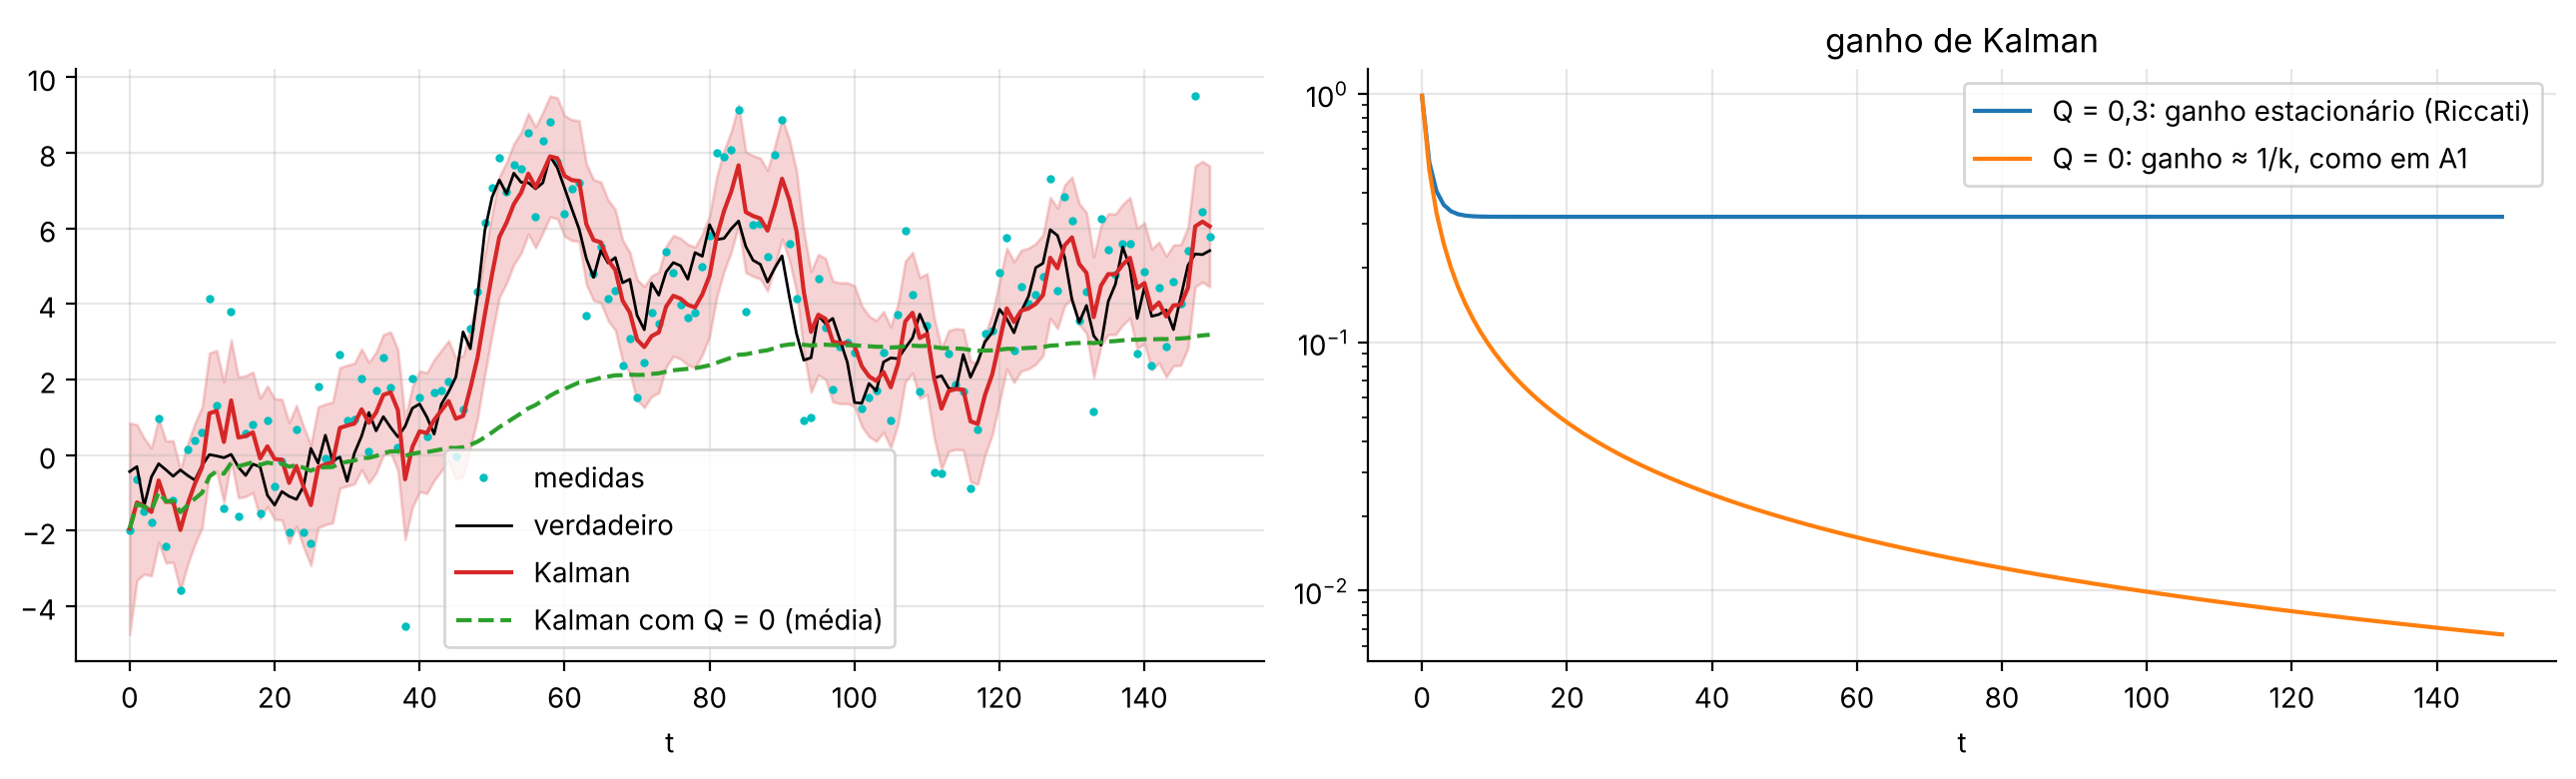

In [27]:
kf0 = kalman(y1[:, None], I1, I1, 0*I1, r1*I1, np.zeros(1), 100*I1)     # Q = 0: volta à média de A1

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sd = np.sqrt(kf1["Pf"][:, 0, 0])
ax[0].plot(y1, "c.", ms=4, label="medidas"); ax[0].plot(x1, "k-", lw=1, label="verdadeiro")
ax[0].plot(kf1["mf"][:, 0], "C3", label="Kalman"); ax[0].fill_between(range(T1), kf1["mf"][:, 0]-2*sd, kf1["mf"][:, 0]+2*sd, color="C3", alpha=.2)
ax[0].plot(kf0["mf"][:, 0], "C2--", label="Kalman com Q = 0 (média)"); ax[0].legend(); ax[0].set_xlabel("t")
ax[1].plot(kf1["K"][:, 0, 0], label="Q = 0,3: ganho estacionário (Riccati)")
ax[1].plot(kf0["K"][:, 0, 0], label="Q = 0: ganho ≈ 1/k, como em A1")
ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("ganho de Kalman"); ax[1].set_xlabel("t")
plt.tight_layout(); plt.show()

### Três conferências finais

1. **Com $Q=0$, o filtro é a média das medidas.** A conferência não é exata, porque o *prior* $P_0=100$ entra como uma "pseudo-medida" de peso $R/P_0 = 0{,}02$. Fica muito próxima da média simples.
2. **Ganho estacionário.** O valor de $P^-$ em regime satisfaz a **equação de Riccati** escalar, $P^- = \dfrac{P^-R}{P^-+R}+Q$. A solução positiva é $P^- = \dfrac{Q+\sqrt{Q^2+4QR}}{2}$, e daí $K_\infty = P^-/(P^-+R)$.
3. **Calibração.** Que fração dos instantes tem a verdade dentro de $\pm2\sigma$? O esperado é cerca de 95%.

In [28]:
media_acum = np.cumsum(y1) / np.arange(1, T1 + 1)
print(f"1. Q = 0:  |m_t − média(y_0..y_t)| máximo = {np.max(np.abs(kf0['mf'][:, 0] - media_acum)):.4f}"
      f"   (pequeno, não zero: efeito do prior P0 = 100)")

Pm_inf = (q1 + np.sqrt(q1**2 + 4*q1*r1)) / 2
K_inf = Pm_inf / (Pm_inf + r1)
print(f"2. Riccati:  P⁻∞ = {Pm_inf:.4f},  K∞ = {K_inf:.4f}   |   filtro em t = 149:  P⁻ = {kf1['Pp'][-1, 0, 0]:.4f},  K = {kf1['K'][-1, 0, 0]:.4f}")

dentro = np.abs(x1 - kf1["mf"][:, 0]) <= 2*np.sqrt(kf1["Pf"][:, 0, 0])
print(f"3. calibração:  verdade dentro de ±2σ em {100*dentro.mean():.1f}% dos instantes (esperado ≈ 95%)")

1. Q = 0:  |m_t − média(y_0..y_t)| máximo = 0.0389   (pequeno, não zero: efeito do prior P0 = 100)
2. Riccati:  P⁻∞ = 0.9390,  K∞ = 0.3195   |   filtro em t = 149:  P⁻ = 0.9390,  K = 0.3195
3. calibração:  verdade dentro de ±2σ em 92.7% dos instantes (esperado ≈ 95%)


## Para experimentar

1. Mude `r1` para 0,2 (sensor bom) e depois para 20 (sensor ruim). Rode de novo e observe o ganho estacionário e a suavidade da curva vermelha.
2. Use `q1 = 0.3` para simular, mas passe `0.03*I1` como `Q` para o filtro (um modelo que subestima o movimento). O que acontece com a calibração?
3. Troque `P0 = 100*I1` por `P0 = 0.01*I1` e `m0` por `np.array([5.0])` (um *prior* confiante e errado). Quantas medidas o filtro leva para se recuperar? Compare com o exemplo de Bell & Cathey na seção C5b do notebook principal.